# RankUp pada Semua Dataset

Notebook Kaggle ini membandingkan **MLP**, **TabM**, dan **RealMLP** pada lima dataset ordinal. Setiap kombinasi model–dataset menjalankan empat eksperimen:

1. **Supervised** — hanya `N_LABEL` data berlabel.
2. **Fully-Supervised** — semua label train; upper bound.
3. **RankUp + FESTA** — data tanpa label diberi dua augmentasi range-limited.
4. **RankUp + TabCutMix** — data tanpa label diberi dua augmentasi pertukaran fitur.

Metrik test: **R² ↑, Spearman ↑, MAE ↓, RMSE ↓, QWK ↑**. Satu split dan satu seed dipakai agar perbandingan adil.

## 1. Setup

In [1]:
%pip install -q tabm

import gc
import random
import time
from itertools import cycle, islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr
from sklearn.metrics import (
    cohen_kappa_score, mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from tabm import TabM
from torch.utils.data import DataLoader, TensorDataset

sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
N_LABEL = 200
EPOCHS = 120
BATCH_SIZE = 32             
SUPERVISED_BATCH_SIZE = 256
MAX_RANKUP_STEPS = 100      
LOG_EVERY = 10
W_RANK = 0.2
W_UNLABELED = 0.2
P_CUTOFF = 0.95
FESTA_BINS = 10
TSNE_MAX_SAMPLES = 500

DATASET_FILES = {
    "Melbourne Airbnb": "oc10_melbourneAirbnb.csv",
    "Student Performance": "oc08_studentPerformance.csv",
    "NHANES": "oc05_nhanes.csv",
    "ESL": "oc06_esl.csv",
    "LEV": "oc05_lev.csv",
}
MODELS = ["MLP", "TabM", "RealMLP"]
EXPERIMENTS = ["Supervised", "Fully-Supervised", "RankUp + FESTA", "RankUp + TabCutMix"]

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUTPUT_DIR = WORK_DIR / "rankup_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | jumlah GPU tersedia: {torch.cuda.device_count()}")

Note: you may need to restart the kernel to use updated packages.
Device: cuda:0
GPU: Tesla T4 | jumlah GPU tersedia: 2


## 2. Memuat seluruh dataset

Pencarian file mendukung struktur lokal `dataset/` dan folder Kaggle `/kaggle/input/`. Semua fitur harus numerik dan target harus bernama `y` dengan kelas ordinal berurutan mulai dari 0.

In [2]:
def find_dataset(filename):
    for root in [Path("dataset"), Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            match = next(root.rglob(filename), None)
            if match is not None:
                return match
    raise FileNotFoundError(f"{filename} tidak ditemukan")


datasets = {}
for name, filename in DATASET_FILES.items():
    path = find_dataset(filename)
    df = pd.read_csv(path)
    if "y" not in df.columns or df.isna().any().any():
        raise ValueError(f"{name}: target 'y' wajib ada dan data tidak boleh missing")
    if len(df.select_dtypes(include=np.number).columns) != len(df.columns):
        raise ValueError(f"{name}: semua kolom harus numerik")
    classes = np.sort(df["y"].unique())
    if not np.array_equal(classes, np.arange(len(classes))):
        raise ValueError(f"{name}: kelas harus 0..K-1, ditemukan {classes.tolist()}")
    datasets[name] = df
    print(f"{name:20} | {df.shape[0]:6,} baris | {df.shape[1] - 1:2} fitur | {len(classes)} kelas")

Melbourne Airbnb     | 20,036 baris | 48 fitur | 10 kelas
Student Performance  |    662 baris | 43 fitur | 8 kelas
NHANES               |  5,223 baris | 30 fitur | 5 kelas
ESL                  |    488 baris |  4 fitur | 6 kelas
LEV                  |  1,000 baris |  4 fitur | 5 kelas


## 3. Split dan preprocessing

In [3]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def prepare_data(df):
    X = df.drop(columns="y").to_numpy(dtype=np.float32)
    y = df["y"].to_numpy(dtype=np.float32)
    indices = np.arange(len(df))
    train_idx, test_idx = train_test_split(
        indices, test_size=0.2, random_state=SEED, stratify=y
    )
    if N_LABEL >= len(train_idx):
        raise ValueError(f"N_LABEL={N_LABEL} harus lebih kecil dari train={len(train_idx)}")
    labeled_idx, unlabeled_idx = train_test_split(
        train_idx, train_size=N_LABEL, random_state=SEED, stratify=y[train_idx]
    )

    x_scaler = StandardScaler().fit(X[train_idx])
    y_scaler = StandardScaler().fit(y[labeled_idx, None])
    X_scaled = x_scaler.transform(X).astype(np.float32)
    y_scaled = y_scaler.transform(y[:, None]).astype(np.float32)

    tensor = lambda value: torch.from_numpy(value)
    return {
        "x_labeled": tensor(X_scaled[labeled_idx]),
        "y_labeled": tensor(y_scaled[labeled_idx]),
        "x_unlabeled": tensor(X_scaled[unlabeled_idx]),
        "x_train": tensor(X_scaled[train_idx]),
        "y_train": tensor(y_scaled[train_idx]),
        "x_test": tensor(X_scaled[test_idx]),
        "y_test": y[test_idx].astype(int),
        "y_scaler": y_scaler,
        "n_features": X.shape[1],
        "class_min": int(y.min()),
        "class_max": int(y.max()),
    }


prepared = {name: prepare_data(df) for name, df in datasets.items()}
for name, data in prepared.items():
    print(f"{name:20} | labeled={len(data['x_labeled'])} | unlabeled={len(data['x_unlabeled'])} | test={len(data['x_test'])}")

Melbourne Airbnb     | labeled=200 | unlabeled=15828 | test=4008
Student Performance  | labeled=200 | unlabeled=329 | test=133
NHANES               | labeled=200 | unlabeled=3978 | test=1045
ESL                  | labeled=200 | unlabeled=190 | test=98
LEV                  | labeled=200 | unlabeled=600 | test=200


## 4. Model

Ketiga model mempunyai satu output regresi dan dua logit ranking. Pada TabM, `k` anggota ensemble dilatih independen sesuai dokumentasi resmi; rata-rata hanya dipakai saat inference.

In [4]:
class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
        )
        self.regressor = nn.Linear(32, 1)
        self.ranker = nn.Linear(32, 2)

    def forward(self, x):
        z = self.encode(x)
        return self.regressor(z), self.ranker(z)

    def encode(self, x):
        return self.encoder(x)


class NTPLinear(nn.Module):
    def __init__(self, in_features, out_features, zero_init=False):
        super().__init__()
        factor = 0.0 if zero_init else 1.0
        self.weight = nn.Parameter(factor * torch.randn(in_features, out_features))
        self.bias = nn.Parameter(factor * torch.randn(1, out_features))
        self.scale = in_features ** -0.5

    def forward(self, x):
        return self.scale * (x @ self.weight) + self.bias


class RealMLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.scale = nn.Parameter(torch.ones(n_features))
        layers = []
        width = n_features
        for _ in range(3):
            layers += [NTPLinear(width, 256), nn.Mish()]
            width = 256
        self.encoder = nn.Sequential(*layers)
        self.regressor = NTPLinear(width, 1, zero_init=True)
        self.ranker = NTPLinear(width, 2, zero_init=True)

    def forward(self, x):
        z = self.encode(x)
        return self.regressor(z), self.ranker(z)

    def encode(self, x):
        return self.encoder(x * self.scale)


class TabMRankUp(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.model = TabM.make(n_num_features=n_features, d_out=3)

    def forward(self, x):
        output = self.model(x)             # (batch, k, 3)
        return output[..., :1], output[..., 1:]

    def encode(self, x):
        # Semua fitur numerik, jadi input dapat langsung masuk ensemble backbone.
        z = self.model.backbone(self.model.ensemble_view(x))
        return z.mean(dim=1)






## 5. Augmentasi unlabeled

FESTA mengambil nilai acak di dalam bin kuantil fitur yang sama. TabCutMix menukar subset fitur dengan baris donor acak. Probabilitas kecil membentuk weak view, probabilitas lebih besar membentuk strong view.

In [5]:
def festa_edges(x_train, n_bins=FESTA_BINS):
    quantiles = torch.linspace(0, 1, n_bins + 1)
    return torch.stack([torch.quantile(x_train[:, j], quantiles) for j in range(x_train.shape[1])])


def festa_view(x, edges, probability):
    bin_id = torch.stack([
        torch.bucketize(x[:, j].contiguous(), edges[j, 1:-1].contiguous())
        for j in range(x.shape[1])
    ], dim=1)
    low = edges.gather(1, bin_id.T).T
    high = edges.gather(1, (bin_id + 1).T).T
    sampled = low + torch.rand_like(x) * (high - low)
    return torch.where(torch.rand_like(x) < probability, sampled, x)


def tabcutmix_view(x, probability):
    donor = x[torch.randperm(len(x), device=x.device)]
    return torch.where(torch.rand_like(x) < probability, donor, x)




## 6. Loss RankUp dan evaluasi

Regression loss memakai MAE. Ranking target pasangan adalah 1 jika target pertama lebih besar, 0 jika lebih kecil, dan 0.5 jika sama. QWK memakai prediksi kontinu yang dibulatkan dan di-clip ke rentang kelas; metrik lain tetap memakai skor kontinu.

In [6]:
def regression_loss(prediction, target):
    if prediction.ndim == 3:
        target = target[:, None, :].expand_as(prediction)
    return F.l1_loss(prediction, target)


def pairwise_logits(rank_logits):
    if rank_logits.ndim == 2:
        return rank_logits[:, None, :] - rank_logits[None, :, :]
    rank_logits = rank_logits.permute(1, 0, 2)
    return rank_logits[:, :, None, :] - rank_logits[:, None, :, :]


def pairwise_targets(target):
    difference = target[:, None, 0] - target[None, :, 0]
    probability = (difference > 0).float() + 0.5 * (difference == 0).float()
    return torch.stack([1 - probability, probability], dim=-1)


def supervised_rank_loss(rank_logits, target):
    logits = pairwise_logits(rank_logits)
    targets = pairwise_targets(target)
    if logits.ndim == 4:
        targets = targets.unsqueeze(0).expand(logits.shape[0], -1, -1, -1)
    return F.cross_entropy(logits.reshape(-1, 2), targets.reshape(-1, 2))


def pseudo_rank_loss(weak_logits, strong_logits):
    weak_pairs = pairwise_logits(weak_logits)
    weak_probability = F.softmax(weak_pairs, dim=-1)
    if weak_probability.ndim == 4:
        weak_probability = weak_probability.mean(0)
    confidence, pseudo_target = weak_probability.max(dim=-1)

    strong_pairs = pairwise_logits(strong_logits)
    if strong_pairs.ndim == 4:
        pseudo_target = pseudo_target.unsqueeze(0).expand(strong_pairs.shape[0], -1, -1)
        confidence = confidence.unsqueeze(0).expand(strong_pairs.shape[0], -1, -1)
    loss = F.cross_entropy(
        strong_pairs.reshape(-1, 2), pseudo_target.reshape(-1), reduction="none"
    )
    mask = confidence.reshape(-1) >= P_CUTOFF
    return (loss[mask].mean() if mask.any() else loss.sum() * 0), mask.float().mean().item()


def evaluate(y_true, score, class_min, class_max):
    prediction = np.clip(np.rint(score), class_min, class_max).astype(int)
    spearman = spearmanr(y_true, score).statistic
    return {
        "R2": r2_score(y_true, score),
        "Spearman": 0.0 if np.isnan(spearman) else spearman,
        "MAE": mean_absolute_error(y_true, score),
        "RMSE": mean_squared_error(y_true, score) ** 0.5,
        "QWK": cohen_kappa_score(y_true, prediction, weights="quadratic"),
    }


# Self-check singkat untuk arah pasangan dan bentuk augmentasi.
demo_x = torch.tensor([[0.0, 1.0], [1.0, 0.0], [2.0, 2.0]])
demo_y = torch.tensor([[0.0], [1.0], [2.0]])
assert pairwise_targets(demo_y)[2, 0, 1] == 1
assert festa_view(demo_x, festa_edges(demo_x, 2), 0.5).shape == demo_x.shape
assert tabcutmix_view(demo_x, 0.5).shape == demo_x.shape
print("Self-check RankUp dan augmentasi: OK")

Self-check RankUp dan augmentasi: OK


## 7. DataLoader dan inference

Fungsi kecil ini hanya menyiapkan batch, prediksi test, dan hidden feature untuk t-SNE. Training loop tetap ditulis langsung di setiap bagian eksperimen.

In [7]:
def make_loader(x, y=None, batch_size=BATCH_SIZE, shuffle=True):
    dataset = TensorDataset(x) if y is None else TensorDataset(x, y)
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED), pin_memory=torch.cuda.is_available(),
    )


def predict(model, data):
    loader = make_loader(data["x_test"], batch_size=1024, shuffle=False)
    predictions = []
    model.eval()
    with torch.inference_mode():
        for (x,) in loader:
            prediction, _ = model(x.to(DEVICE, non_blocking=True))
            if prediction.ndim == 3:
                prediction = prediction.mean(dim=1)
            predictions.append(prediction.cpu().numpy())
    scaled = np.concatenate(predictions).reshape(-1, 1)
    return data["y_scaler"].inverse_transform(scaled).ravel()


def extract_features(model, data):
    loader = make_loader(data["x_test"], batch_size=1024, shuffle=False)
    features = []
    model.eval()
    with torch.inference_mode():
        for (x,) in loader:
            features.append(model.encode(x.to(DEVICE, non_blocking=True)).cpu().numpy())
    return np.concatenate(features)

## 8. Menyiapkan penyimpanan hasil

List berikut menampung metrik, prediksi, history, dan representasi fitur dari semua cell eksperimen.

In [8]:
results, predictions, histories = [], [], []
representations = {}
results_df = predictions_df = history_df = pd.DataFrame()

## 9. Helper visualisasi

Setiap fungsi membuat satu jenis visualisasi seperti notebook referensi. Fungsi yang sama dipakai oleh ketiga model agar warna, skala, judul, dan file output konsisten.

In [9]:
PALETTE = dict(zip(EXPERIMENTS, sns.color_palette("colorblind", len(EXPERIMENTS))))
METRICS = ["R2", "Spearman", "MAE", "RMSE", "QWK"]


def show_model_summary(model_name):
    columns = ["dataset", "experiment", *METRICS, "training_seconds", "inference_seconds"]
    table = results_df[results_df["model"] == model_name][columns]
    display(table.reset_index(drop=True).style.format({
        **{metric: "{:.4f}" for metric in METRICS},
        "training_seconds": "{:.1f}", "inference_seconds": "{:.3f}",
    }))


def plot_metrics(model_name):
    for dataset_name in DATASET_FILES:
        subset = results_df.query("model == @model_name and dataset == @dataset_name")
        figure, axes = plt.subplots(1, 5, figsize=(24, 4.5))
        for axis, metric in zip(axes, METRICS):
            sns.barplot(
                data=subset, x="experiment", y=metric, hue="experiment",
                order=EXPERIMENTS, hue_order=EXPERIMENTS, palette=PALETTE, legend=False, ax=axis,
            )
            axis.set_title(metric + (" ↓" if metric in ["MAE", "RMSE"] else " ↑"))
            axis.set_xlabel("")
            axis.tick_params(axis="x", rotation=25)
        figure.suptitle(f"{model_name} — {dataset_name}", y=1.04, fontsize=15)
        figure.tight_layout()
        filename = DATASET_FILES[dataset_name][:-4]
        figure.savefig(OUTPUT_DIR / f"metrics_{model_name.lower()}_{filename}.png", dpi=150, bbox_inches="tight")
        plt.show()


def plot_training(model_name):
    for dataset_name in DATASET_FILES:
        subset = history_df.query("model == @model_name and dataset == @dataset_name")
        rankup = subset[subset["experiment"].str.startswith("RankUp")]
        rank_losses = rankup.melt(
            id_vars=["epoch", "experiment"],
            value_vars=["rank_labeled", "rank_unlabeled"],
            var_name="component", value_name="value",
        )

        figure, axes = plt.subplots(1, 3, figsize=(18, 4.5))
        sns.lineplot(data=subset, x="epoch", y="loss", hue="experiment", palette=PALETTE, ax=axes[0])
        sns.lineplot(data=rank_losses, x="epoch", y="value", hue="experiment", style="component", palette=PALETTE, ax=axes[1])
        sns.lineplot(data=rankup, x="epoch", y="accepted", hue="experiment", palette=PALETTE, ax=axes[2])
        axes[0].set_title("Total training loss")
        axes[1].set_title("Breakdown ranking loss")
        axes[2].set_title("Pasangan pseudo-label diterima")
        axes[2].set_ylim(0, 1)
        figure.suptitle(f"{model_name} — {dataset_name}", y=1.04, fontsize=15)
        figure.tight_layout()
        filename = DATASET_FILES[dataset_name][:-4]
        figure.savefig(OUTPUT_DIR / f"loss_{model_name.lower()}_{filename}.png", dpi=150, bbox_inches="tight")
        plt.show()


def plot_predictions(model_name):
    for dataset_name in DATASET_FILES:
        subset = predictions_df.query("model == @model_name and dataset == @dataset_name")
        low = subset[["y_true", "y_score"]].min().min()
        high = subset[["y_true", "y_score"]].max().max()
        figure, axes = plt.subplots(1, 2, figsize=(13, 5))
        sns.scatterplot(data=subset, x="y_true", y="y_score", hue="experiment", palette=PALETTE, alpha=0.45, ax=axes[0])
        axes[0].plot([low, high], [low, high], "--", color="black", linewidth=1)
        axes[0].set_title("Prediksi vs target")
        sns.histplot(data=subset, x="residual", hue="experiment", palette=PALETTE, kde=True, bins=20, alpha=0.35, ax=axes[1])
        axes[1].axvline(0, linestyle="--", color="black", linewidth=1)
        axes[1].set_title("Distribusi residual (prediksi − target)")
        figure.suptitle(f"{model_name} — {dataset_name}", y=1.03, fontsize=15)
        figure.tight_layout()
        filename = DATASET_FILES[dataset_name][:-4]
        figure.savefig(OUTPUT_DIR / f"prediction_{model_name.lower()}_{filename}.png", dpi=150, bbox_inches="tight")
        plt.show()


def plot_tsne(model_name):
    rng = np.random.default_rng(SEED)
    for dataset_name, data in prepared.items():
        n_samples = min(TSNE_MAX_SAMPLES, len(data["y_test"]))
        sample_idx = np.sort(rng.choice(len(data["y_test"]), n_samples, replace=False))
        targets = data["y_test"][sample_idx]
        figure, axes = plt.subplots(1, 4, figsize=(20, 4.5), constrained_layout=True)

        for axis, experiment in zip(axes, EXPERIMENTS):
            features = representations[(dataset_name, model_name, experiment)][sample_idx]
            embedding = TSNE(
                n_components=2, perplexity=min(30, n_samples - 1),
                init="pca", learning_rate="auto", random_state=SEED,
            ).fit_transform(features)
            scatter = axis.scatter(embedding[:, 0], embedding[:, 1], c=targets, cmap="viridis", s=18, alpha=0.8)
            axis.set_title(experiment)
            axis.set_xlabel("t-SNE 1")
            axis.set_ylabel("t-SNE 2")

        figure.colorbar(scatter, ax=axes, label="Target ordinal")
        figure.suptitle(f"Representasi fitur {model_name} — {dataset_name}", y=1.05, fontsize=15)
        filename = DATASET_FILES[dataset_name][:-4]
        figure.savefig(OUTPUT_DIR / f"tsne_{model_name.lower()}_{filename}.png", dpi=150, bbox_inches="tight")
        plt.show()

# 10. Eksperimen MLP

MLP pembanding memiliki encoder 64 → 32, regression head, dan ranking head.

## 10.1 Supervised MLP

Hanya `N_LABEL` label dari setiap dataset yang dipakai.

In [10]:
def train_mlp_supervised(data):
    set_seed()
    model = MLP(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = make_loader(data["x_labeled"], data["y_labeled"])
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction, _ = model(x)
            loss = F.l1_loss(prediction, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        history.append({"epoch": epoch, "loss": np.mean(losses)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(losses):.4f}")
    return model, history


experiment = "Supervised"
for dataset_name, data in prepared.items():
    print(f"\nMLP | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_mlp_supervised(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "MLP", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "MLP", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "MLP", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "MLP", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
mlp_supervised = results_df.query("model == 'MLP' and experiment == 'Supervised'")
mlp_supervised


MLP | Supervised | Melbourne Airbnb
  epoch 001/120 | loss=0.8495
  epoch 010/120 | loss=0.3944
  epoch 020/120 | loss=0.3155
  epoch 030/120 | loss=0.2335
  epoch 040/120 | loss=0.1957
  epoch 050/120 | loss=0.1422
  epoch 060/120 | loss=0.1512
  epoch 070/120 | loss=0.1307
  epoch 080/120 | loss=0.0921
  epoch 090/120 | loss=0.0833
  epoch 100/120 | loss=0.0924
  epoch 110/120 | loss=0.0701
  epoch 120/120 | loss=0.0801
{'R2': 0.3074, 'Spearman': 0.6979, 'MAE': 1.7716, 'RMSE': 2.4998, 'QWK': 0.6926}

MLP | Supervised | Student Performance
  epoch 001/120 | loss=0.8177
  epoch 010/120 | loss=0.5864
  epoch 020/120 | loss=0.4475
  epoch 030/120 | loss=0.3052
  epoch 040/120 | loss=0.2231
  epoch 050/120 | loss=0.1765
  epoch 060/120 | loss=0.1354
  epoch 070/120 | loss=0.1113
  epoch 080/120 | loss=0.0890
  epoch 090/120 | loss=0.0799
  epoch 100/120 | loss=0.0736
  epoch 110/120 | loss=0.0701
  epoch 120/120 | loss=0.0554
{'R2': -0.4009, 'Spearman': 0.1513, 'MAE': 1.6784, 'RMSE': 2.0

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
0,Melbourne Airbnb,MLP,Supervised,42,Tesla T4,7.729470,0.018389,0.307437,0.697880,1.771598,2.499750,0.692592
1,Student Performance,MLP,Supervised,42,Tesla T4,1.474345,0.001550,-0.400904,0.151293,1.678441,2.098219,0.096304
2,NHANES,MLP,Supervised,42,Tesla T4,1.533110,0.004105,-0.323792,0.238788,0.891992,1.137975,0.203496
3,ESL,MLP,Supervised,42,Tesla T4,1.541713,0.001248,0.858848,0.925188,0.366505,0.503486,0.907080
4,LEV,MLP,Supervised,42,Tesla T4,1.531660,0.001535,0.505073,0.705884,0.466899,0.669029,0.665341


## 10.2 Fully-Supervised MLP

Semua label train dipakai sebagai upper bound.

In [11]:
def train_mlp_fully_supervised(data):
    set_seed()
    model = MLP(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = make_loader(data["x_train"], data["y_train"], SUPERVISED_BATCH_SIZE)
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction, _ = model(x)
            loss = F.l1_loss(prediction, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        history.append({"epoch": epoch, "loss": np.mean(losses)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(losses):.4f}")
    return model, history


experiment = "Fully-Supervised"
for dataset_name, data in prepared.items():
    print(f"\nMLP | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_mlp_fully_supervised(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "MLP", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "MLP", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "MLP", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "MLP", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
mlp_fully = results_df.query("model == 'MLP' and experiment == 'Fully-Supervised'")
mlp_fully


MLP | Fully-Supervised | Melbourne Airbnb
  epoch 001/120 | loss=0.6303
  epoch 010/120 | loss=0.4068
  epoch 020/120 | loss=0.3848
  epoch 030/120 | loss=0.3683
  epoch 040/120 | loss=0.3583
  epoch 050/120 | loss=0.3497
  epoch 060/120 | loss=0.3429
  epoch 070/120 | loss=0.3377
  epoch 080/120 | loss=0.3334
  epoch 090/120 | loss=0.3276
  epoch 100/120 | loss=0.3241
  epoch 110/120 | loss=0.3219
  epoch 120/120 | loss=0.3203
{'R2': 0.6894, 'Spearman': 0.8289, 'MAE': 1.212, 'RMSE': 1.6739, 'QWK': 0.8268}

MLP | Fully-Supervised | Student Performance
  epoch 001/120 | loss=0.7657
  epoch 010/120 | loss=0.7228
  epoch 020/120 | loss=0.6546
  epoch 030/120 | loss=0.6127
  epoch 040/120 | loss=0.6223
  epoch 050/120 | loss=0.5073
  epoch 060/120 | loss=0.5014
  epoch 070/120 | loss=0.3966
  epoch 080/120 | loss=0.3845
  epoch 090/120 | loss=0.3904
  epoch 100/120 | loss=0.3741
  epoch 110/120 | loss=0.2635
  epoch 120/120 | loss=0.2615
{'R2': -0.1643, 'Spearman': 0.2424, 'MAE': 1.4591, 

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
5,Melbourne Airbnb,MLP,Fully-Supervised,42,Tesla T4,22.190223,0.013154,0.689445,0.828906,1.211958,1.673927,0.826795
6,Student Performance,MLP,Fully-Supervised,42,Tesla T4,0.936739,0.001259,-0.164291,0.242410,1.459055,1.912835,0.202672
7,NHANES,MLP,Fully-Supervised,42,Tesla T4,5.741587,0.004478,-0.007502,0.294233,0.786182,0.992764,0.258883
8,ESL,MLP,Fully-Supervised,42,Tesla T4,0.649444,0.001233,0.854638,0.929262,0.391594,0.510939,0.898734
9,LEV,MLP,Fully-Supervised,42,Tesla T4,1.294451,0.001404,0.517984,0.735065,0.436802,0.660245,0.707391


## 10.3 RankUp + FESTA MLP

`N_LABEL` label melatih regresi dan ranking supervised; sisa train dipakai melalui pseudo-ranking dengan range-limited augmentation.

In [12]:
def train_mlp_rankup_festa(data):
    set_seed()
    model = MLP(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    labeled_loader = make_loader(data["x_labeled"], data["y_labeled"])
    unlabeled_loader = make_loader(data["x_unlabeled"])
    edges = festa_edges(data["x_train"]).to(DEVICE)
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        totals, rank_labs, rank_unlabs, accepted = [], [], [], []
        labeled_batches = cycle(labeled_loader)
        for (x_u,) in islice(unlabeled_loader, MAX_RANKUP_STEPS):
            x_l, y_l = next(labeled_batches)
            x_l, y_l, x_u = x_l.to(DEVICE), y_l.to(DEVICE), x_u.to(DEVICE)
            weak = festa_view(x_u, edges, 0.1)
            strong = festa_view(x_u, edges, 0.3)

            optimizer.zero_grad(set_to_none=True)
            pred_l, rank_l = model(x_l)
            loss_reg = F.l1_loss(pred_l, y_l)
            loss_rank_lab = supervised_rank_loss(rank_l, y_l)
            with torch.no_grad():
                _, rank_weak = model(weak)
            _, rank_strong = model(strong)
            loss_rank_unlab, accept_rate = pseudo_rank_loss(rank_weak, rank_strong)
            loss = loss_reg + W_RANK * loss_rank_lab + W_UNLABELED * loss_rank_unlab
            loss.backward()
            optimizer.step()
            totals.append(loss.item())
            rank_labs.append(loss_rank_lab.item())
            rank_unlabs.append(loss_rank_unlab.item())
            accepted.append(accept_rate)
        history.append({"epoch": epoch, "loss": np.mean(totals), "rank_labeled": np.mean(rank_labs), "rank_unlabeled": np.mean(rank_unlabs), "accepted": np.mean(accepted)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(totals):.4f} | accepted={np.mean(accepted):.1%}")
    return model, history


experiment = "RankUp + FESTA"
for dataset_name, data in prepared.items():
    print(f"\nMLP | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_mlp_rankup_festa(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "MLP", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "MLP", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "MLP", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "MLP", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
mlp_festa = results_df.query("model == 'MLP' and experiment == 'RankUp + FESTA'")
mlp_festa


MLP | RankUp + FESTA | Melbourne Airbnb
  epoch 001/120 | loss=0.6521 | accepted=2.0%
  epoch 010/120 | loss=0.1170 | accepted=61.3%
  epoch 020/120 | loss=0.0904 | accepted=68.3%
  epoch 030/120 | loss=0.0869 | accepted=71.2%
  epoch 040/120 | loss=0.0780 | accepted=72.6%
  epoch 050/120 | loss=0.0696 | accepted=73.2%
  epoch 060/120 | loss=0.0799 | accepted=72.9%
  epoch 070/120 | loss=0.0725 | accepted=74.8%
  epoch 080/120 | loss=0.0665 | accepted=74.8%
  epoch 090/120 | loss=0.0707 | accepted=74.6%
  epoch 100/120 | loss=0.0645 | accepted=75.1%
  epoch 110/120 | loss=0.0636 | accepted=75.1%
  epoch 120/120 | loss=0.0691 | accepted=75.6%
{'R2': 0.1333, 'Spearman': 0.6799, 'MAE': 1.8667, 'RMSE': 2.7964, 'QWK': 0.6824}

MLP | RankUp + FESTA | Student Performance
  epoch 001/120 | loss=0.9156 | accepted=0.0%
  epoch 010/120 | loss=0.5870 | accepted=1.0%
  epoch 020/120 | loss=0.3467 | accepted=23.5%
  epoch 030/120 | loss=0.2131 | accepted=39.0%
  epoch 040/120 | loss=0.1527 | accept

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
10,Melbourne Airbnb,MLP,RankUp + FESTA,42,Tesla T4,93.415561,0.013308,0.133295,0.679924,1.866718,2.796422,0.682419
11,Student Performance,MLP,RankUp + FESTA,42,Tesla T4,9.930029,0.001299,-0.608487,0.131017,1.775128,2.248306,0.114413
12,NHANES,MLP,RankUp + FESTA,42,Tesla T4,77.590041,0.004065,-0.444841,0.257503,0.936966,1.188866,0.220840
13,ESL,MLP,RankUp + FESTA,42,Tesla T4,3.594637,0.001430,0.859000,0.926461,0.366671,0.503214,0.900621
14,LEV,MLP,RankUp + FESTA,42,Tesla T4,10.837442,0.001782,0.463674,0.708929,0.465448,0.696448,0.695691


## 10.4 RankUp + TabCutMix MLP

Struktur RankUp sama, tetapi weak/strong view dibuat dengan pertukaran subset fitur antarbaris unlabeled.

In [13]:
def train_mlp_rankup_tabcutmix(data):
    set_seed()
    model = MLP(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    labeled_loader = make_loader(data["x_labeled"], data["y_labeled"])
    unlabeled_loader = make_loader(data["x_unlabeled"])
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        totals, rank_labs, rank_unlabs, accepted = [], [], [], []
        labeled_batches = cycle(labeled_loader)
        for (x_u,) in islice(unlabeled_loader, MAX_RANKUP_STEPS):
            x_l, y_l = next(labeled_batches)
            x_l, y_l, x_u = x_l.to(DEVICE), y_l.to(DEVICE), x_u.to(DEVICE)
            weak = tabcutmix_view(x_u, 0.1)
            strong = tabcutmix_view(x_u, 0.5)

            optimizer.zero_grad(set_to_none=True)
            pred_l, rank_l = model(x_l)
            loss_reg = F.l1_loss(pred_l, y_l)
            loss_rank_lab = supervised_rank_loss(rank_l, y_l)
            with torch.no_grad():
                _, rank_weak = model(weak)
            _, rank_strong = model(strong)
            loss_rank_unlab, accept_rate = pseudo_rank_loss(rank_weak, rank_strong)
            loss = loss_reg + W_RANK * loss_rank_lab + W_UNLABELED * loss_rank_unlab
            loss.backward()
            optimizer.step()
            totals.append(loss.item())
            rank_labs.append(loss_rank_lab.item())
            rank_unlabs.append(loss_rank_unlab.item())
            accepted.append(accept_rate)
        history.append({"epoch": epoch, "loss": np.mean(totals), "rank_labeled": np.mean(rank_labs), "rank_unlabeled": np.mean(rank_unlabs), "accepted": np.mean(accepted)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(totals):.4f} | accepted={np.mean(accepted):.1%}")
    return model, history


experiment = "RankUp + TabCutMix"
for dataset_name, data in prepared.items():
    print(f"\nMLP | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_mlp_rankup_tabcutmix(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "MLP", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "MLP", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "MLP", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "MLP", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
mlp_tabcutmix = results_df.query("model == 'MLP' and experiment == 'RankUp + TabCutMix'")
mlp_tabcutmix


MLP | RankUp + TabCutMix | Melbourne Airbnb
  epoch 001/120 | loss=0.6615 | accepted=1.5%
  epoch 010/120 | loss=0.1906 | accepted=32.0%
  epoch 020/120 | loss=0.1783 | accepted=31.3%
  epoch 030/120 | loss=0.1628 | accepted=33.3%
  epoch 040/120 | loss=0.1629 | accepted=32.2%
  epoch 050/120 | loss=0.1526 | accepted=33.6%
  epoch 060/120 | loss=0.1496 | accepted=34.1%
  epoch 070/120 | loss=0.1474 | accepted=35.4%
  epoch 080/120 | loss=0.1467 | accepted=34.3%
  epoch 090/120 | loss=0.1467 | accepted=34.3%
  epoch 100/120 | loss=0.1458 | accepted=33.6%
  epoch 110/120 | loss=0.1415 | accepted=35.4%
  epoch 120/120 | loss=0.1383 | accepted=37.2%
{'R2': 0.5107, 'Spearman': 0.722, 'MAE': 1.6374, 'RMSE': 2.1011, 'QWK': 0.6998}

MLP | RankUp + TabCutMix | Student Performance
  epoch 001/120 | loss=0.9156 | accepted=0.0%
  epoch 010/120 | loss=0.6081 | accepted=0.6%
  epoch 020/120 | loss=0.3969 | accepted=12.2%
  epoch 030/120 | loss=0.3220 | accepted=22.8%
  epoch 040/120 | loss=0.2342 |

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
15,Melbourne Airbnb,MLP,RankUp + TabCutMix,42,Tesla T4,50.210319,0.013049,0.510695,0.722043,1.637387,2.101149,0.699754
16,Student Performance,MLP,RankUp + TabCutMix,42,Tesla T4,5.817447,0.001539,-0.348234,0.175116,1.650555,2.058398,0.173913
17,NHANES,MLP,RankUp + TabCutMix,42,Tesla T4,49.690280,0.003943,-0.120754,0.315440,0.833692,1.047076,0.262117
18,ESL,MLP,RankUp + TabCutMix,42,Tesla T4,3.192189,0.001186,0.860930,0.927512,0.364910,0.499758,0.904194
19,LEV,MLP,RankUp + TabCutMix,42,Tesla T4,9.796074,0.001604,0.505062,0.713011,0.447596,0.669036,0.669286


## 10.5 Hasil dan visualisasi MLP

Tabel, metrik, loss, prediksi, residual, dan representasi fitur ditampilkan setelah seluruh eksperimen MLP selesai.

In [14]:
show_model_summary("MLP")

,dataset,experiment,R2,Spearman,MAE,RMSE,QWK,training_seconds,inference_seconds
0,Melbourne Airbnb,Supervised,0.3074,0.6979,1.7716,2.4998,0.6926,7.7,0.018
1,Student Performance,Supervised,-0.4009,0.1513,1.6784,2.0982,0.0963,1.5,0.002
2,NHANES,Supervised,-0.3238,0.2388,0.8920,1.1380,0.2035,1.5,0.004
3,ESL,Supervised,0.8588,0.9252,0.3665,0.5035,0.9071,1.5,0.001
4,LEV,Supervised,0.5051,0.7059,0.4669,0.6690,0.6653,1.5,0.002
5,Melbourne Airbnb,Fully-Supervised,0.6894,0.8289,1.2120,1.6739,0.8268,22.2,0.013
6,Student Performance,Fully-Supervised,-0.1643,0.2424,1.4591,1.9128,0.2027,0.9,0.001
7,NHANES,Fully-Supervised,-0.0075,0.2942,0.7862,0.9928,0.2589,5.7,0.004
8,ESL,Fully-Supervised,0.8546,0.9293,0.3916,0.5109,0.8987,0.6,0.001
9,LEV,Fully-Supervised,0.5180,0.7351,0.4368,0.6602,0.7074,1.3,0.001


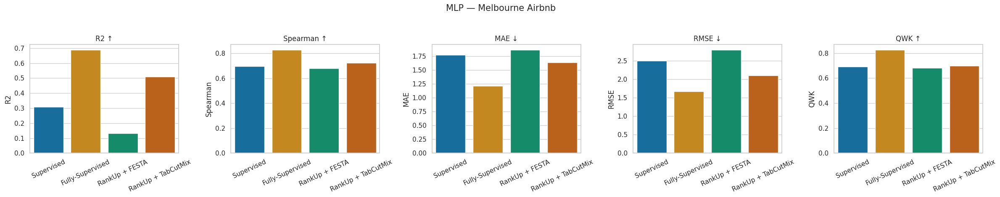

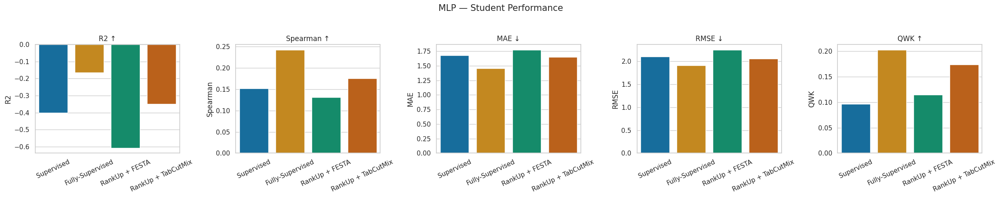

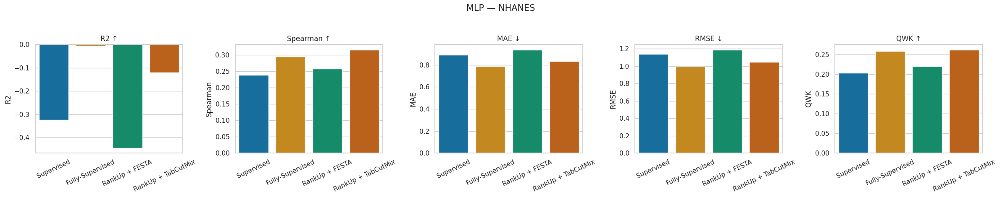

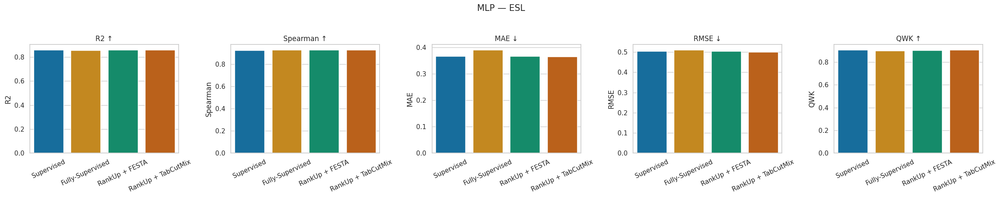

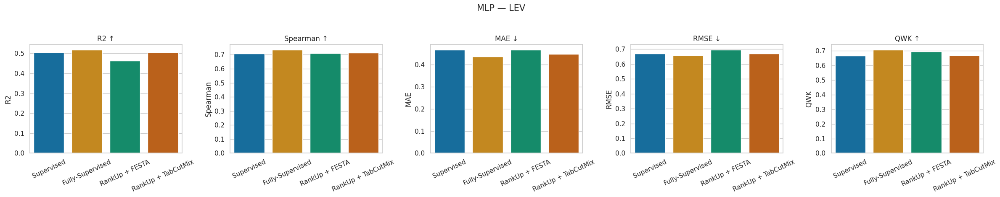

In [15]:
plot_metrics("MLP")

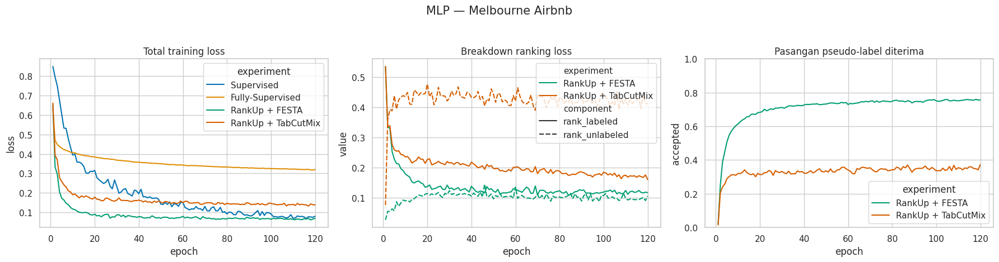

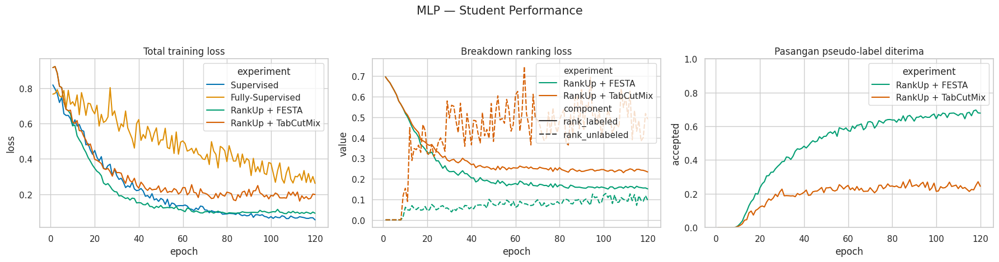

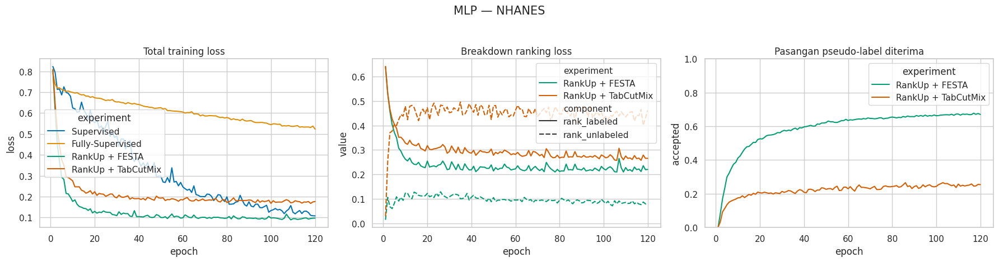

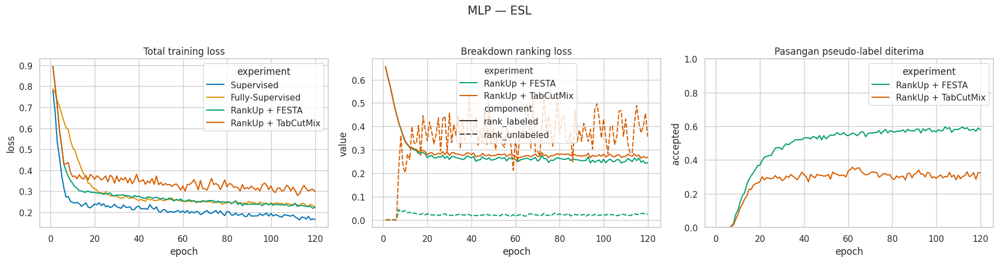

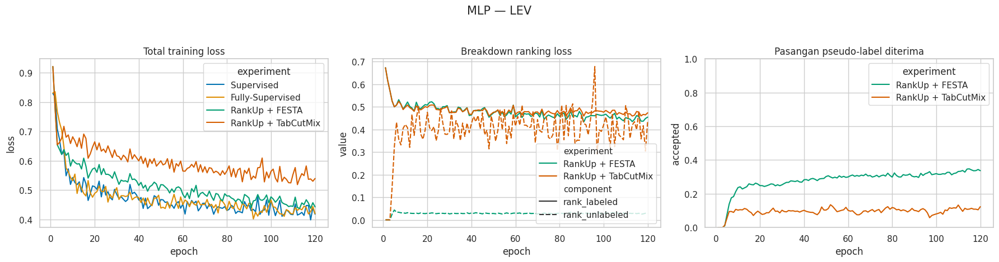

In [16]:
plot_training("MLP")

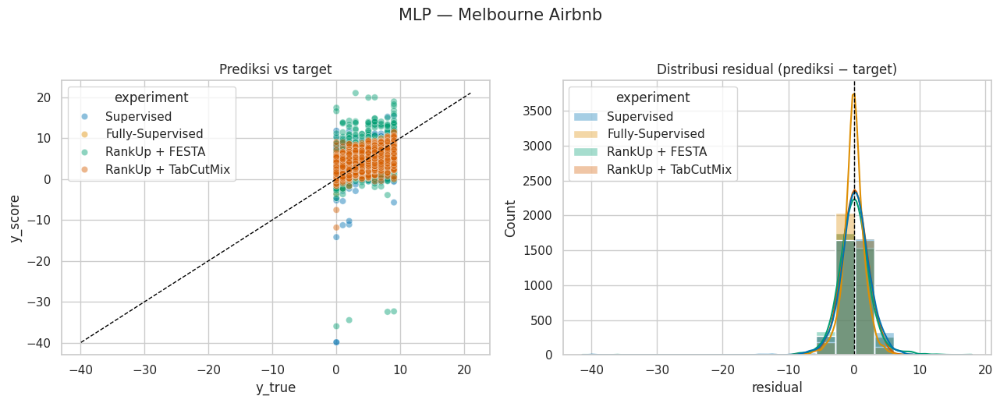

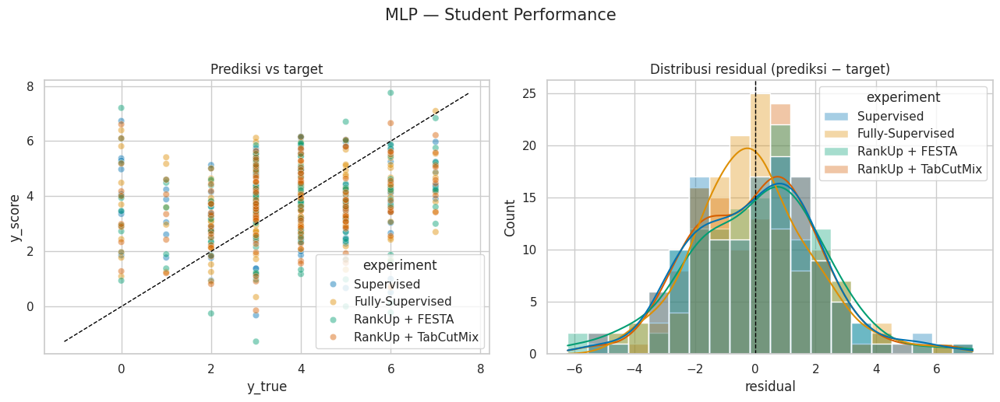

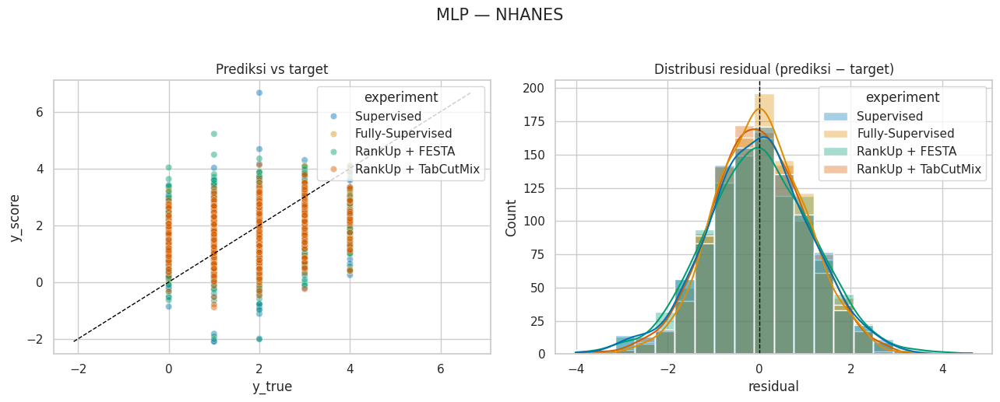

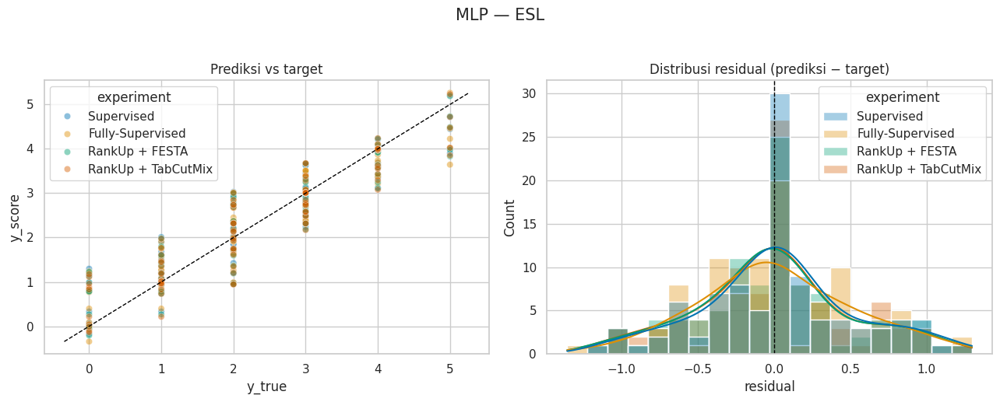

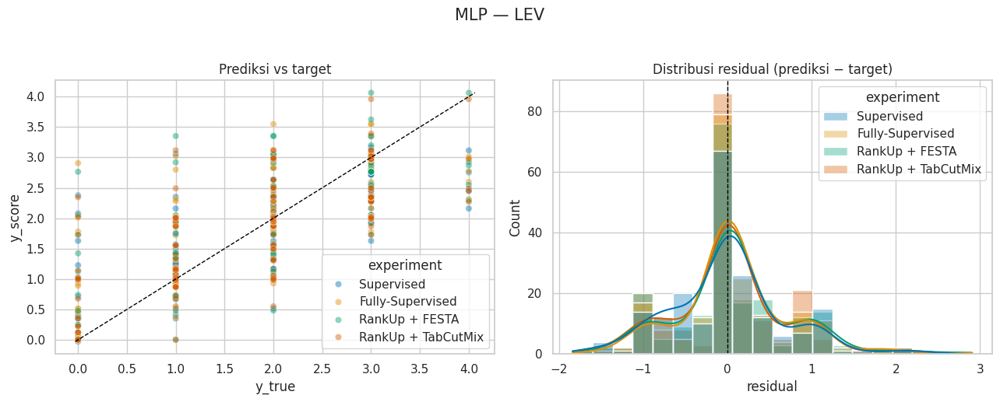

In [17]:
plot_predictions("MLP")

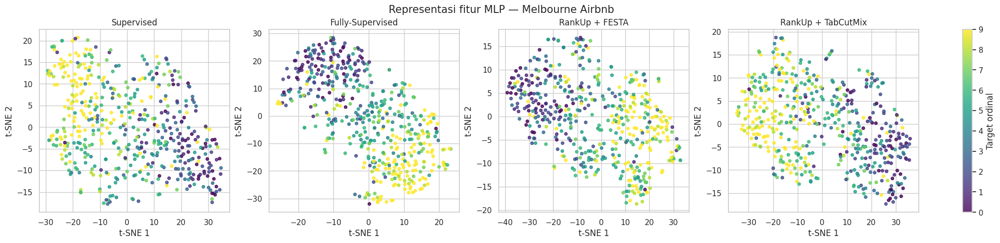

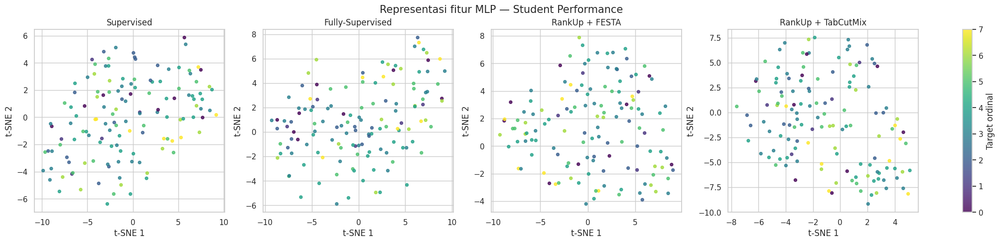

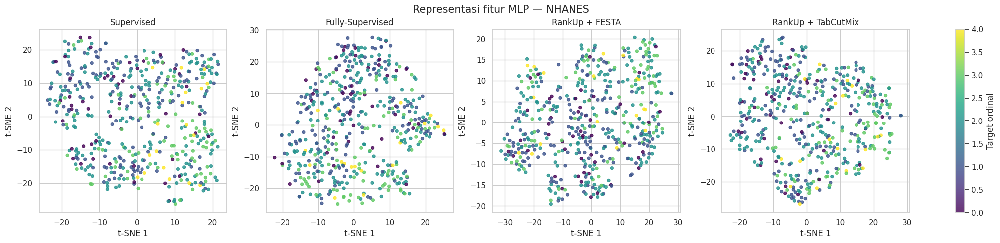

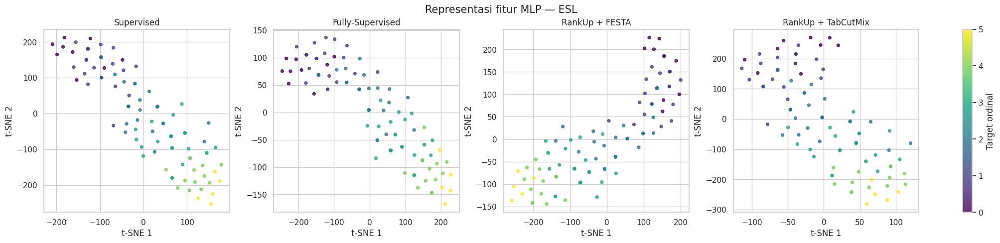

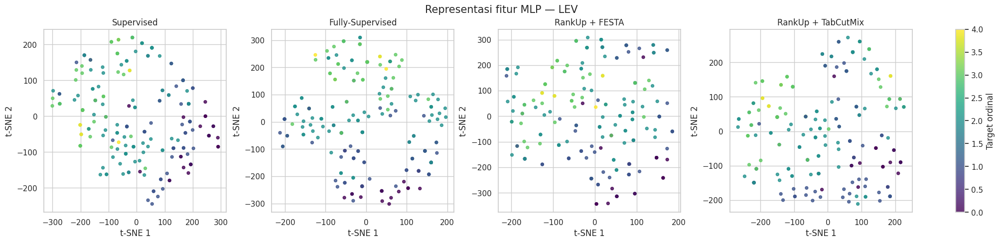

In [18]:
plot_tsne("MLP")

# 11. Eksperimen TabM

TabM memakai ensemble efisien `k` submodel. Loss setiap anggota dihitung independen; prediksi dirata-ratakan saat inference.

## 11.1 Supervised TabM

In [19]:
def train_tabm_supervised(data):
    set_seed()
    model = TabMRankUp(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=3e-4)
    loader = make_loader(data["x_labeled"], data["y_labeled"])
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction, _ = model(x)
            loss = regression_loss(prediction, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        history.append({"epoch": epoch, "loss": np.mean(losses)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(losses):.4f}")
    return model, history


experiment = "Supervised"
for dataset_name, data in prepared.items():
    print(f"\nTabM | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_tabm_supervised(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "TabM", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "TabM", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "TabM", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "TabM", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
tabm_supervised = results_df.query("model == 'TabM' and experiment == 'Supervised'")
tabm_supervised


TabM | Supervised | Melbourne Airbnb
  epoch 001/120 | loss=0.8154
  epoch 010/120 | loss=0.3591
  epoch 020/120 | loss=0.2995
  epoch 030/120 | loss=0.2410
  epoch 040/120 | loss=0.2101
  epoch 050/120 | loss=0.1928
  epoch 060/120 | loss=0.1658
  epoch 070/120 | loss=0.1616
  epoch 080/120 | loss=0.1467
  epoch 090/120 | loss=0.1453
  epoch 100/120 | loss=0.1412
  epoch 110/120 | loss=0.1338
  epoch 120/120 | loss=0.1287
{'R2': 0.5489, 'Spearman': 0.7559, 'MAE': 1.5092, 'RMSE': 2.0175, 'QWK': 0.7428}

TabM | Supervised | Student Performance
  epoch 001/120 | loss=0.8132
  epoch 010/120 | loss=0.5040
  epoch 020/120 | loss=0.3423
  epoch 030/120 | loss=0.2729
  epoch 040/120 | loss=0.2373
  epoch 050/120 | loss=0.2164
  epoch 060/120 | loss=0.1930
  epoch 070/120 | loss=0.1905
  epoch 080/120 | loss=0.1764
  epoch 090/120 | loss=0.1765
  epoch 100/120 | loss=0.1697
  epoch 110/120 | loss=0.1636
  epoch 120/120 | loss=0.1576
{'R2': 0.0389, 'Spearman': 0.3021, 'MAE': 1.367, 'RMSE': 1.7

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
20,Melbourne Airbnb,TabM,Supervised,42,Tesla T4,2.764025,0.068289,0.548891,0.755867,1.509189,2.017474,0.742793
21,Student Performance,TabM,Supervised,42,Tesla T4,2.691760,0.003095,0.038879,0.302101,1.367046,1.737944,0.207936
22,NHANES,TabM,Supervised,42,Tesla T4,2.690796,0.017220,-0.009473,0.284271,0.788767,0.993734,0.232315
23,ESL,TabM,Supervised,42,Tesla T4,2.590266,0.002725,0.823896,0.907472,0.381987,0.562377,0.899099
24,LEV,TabM,Supervised,42,Tesla T4,2.626725,0.003903,0.419595,0.686310,0.489358,0.724502,0.653497


## 11.2 Fully-Supervised TabM

In [20]:
def train_tabm_fully_supervised(data):
    set_seed()
    model = TabMRankUp(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=3e-4)
    loader = make_loader(data["x_train"], data["y_train"], SUPERVISED_BATCH_SIZE)
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction, _ = model(x)
            loss = regression_loss(prediction, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        history.append({"epoch": epoch, "loss": np.mean(losses)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(losses):.4f}")
    return model, history


experiment = "Fully-Supervised"
for dataset_name, data in prepared.items():
    print(f"\nTabM | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_tabm_fully_supervised(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "TabM", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "TabM", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "TabM", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "TabM", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
tabm_fully = results_df.query("model == 'TabM' and experiment == 'Fully-Supervised'")
tabm_fully


TabM | Fully-Supervised | Melbourne Airbnb
  epoch 001/120 | loss=0.5253
  epoch 010/120 | loss=0.3977
  epoch 020/120 | loss=0.3734
  epoch 030/120 | loss=0.3555
  epoch 040/120 | loss=0.3446
  epoch 050/120 | loss=0.3345
  epoch 060/120 | loss=0.3266
  epoch 070/120 | loss=0.3205
  epoch 080/120 | loss=0.3155
  epoch 090/120 | loss=0.3103
  epoch 100/120 | loss=0.3072
  epoch 110/120 | loss=0.3034
  epoch 120/120 | loss=0.3007
{'R2': 0.745, 'Spearman': 0.8595, 'MAE': 1.0801, 'RMSE': 1.5168, 'QWK': 0.8538}

TabM | Fully-Supervised | Student Performance
  epoch 001/120 | loss=0.7772
  epoch 010/120 | loss=0.6793
  epoch 020/120 | loss=0.5765
  epoch 030/120 | loss=0.4886
  epoch 040/120 | loss=0.4961
  epoch 050/120 | loss=0.4284
  epoch 060/120 | loss=0.4047
  epoch 070/120 | loss=0.3635
  epoch 080/120 | loss=0.3559
  epoch 090/120 | loss=0.3404
  epoch 100/120 | loss=0.3057
  epoch 110/120 | loss=0.2858
  epoch 120/120 | loss=0.2763
{'R2': 0.0261, 'Spearman': 0.3741, 'MAE': 1.3426,

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
25,Melbourne Airbnb,TabM,Fully-Supervised,42,Tesla T4,107.039512,0.068971,0.745003,0.859458,1.080094,1.516821,0.853787
26,Student Performance,TabM,Fully-Supervised,42,Tesla T4,3.779944,0.003505,0.026067,0.374130,1.342649,1.749489,0.287126
27,NHANES,TabM,Fully-Supervised,42,Tesla T4,27.356442,0.018904,0.050660,0.313502,0.764122,0.963682,0.230784
28,ESL,TabM,Fully-Supervised,42,Tesla T4,2.612737,0.002915,0.822826,0.910337,0.397304,0.564083,0.892405
29,LEV,TabM,Fully-Supervised,42,Tesla T4,5.332968,0.004188,0.493221,0.738231,0.431408,0.676992,0.701538


## 11.3 RankUp + FESTA TabM

In [21]:
def train_tabm_rankup_festa(data):
    set_seed()
    model = TabMRankUp(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=3e-4)
    labeled_loader = make_loader(data["x_labeled"], data["y_labeled"])
    unlabeled_loader = make_loader(data["x_unlabeled"])
    edges = festa_edges(data["x_train"]).to(DEVICE)
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        totals, rank_labs, rank_unlabs, accepted = [], [], [], []
        labeled_batches = cycle(labeled_loader)
        for (x_u,) in islice(unlabeled_loader, MAX_RANKUP_STEPS):
            x_l, y_l = next(labeled_batches)
            x_l, y_l, x_u = x_l.to(DEVICE), y_l.to(DEVICE), x_u.to(DEVICE)
            weak = festa_view(x_u, edges, 0.1)
            strong = festa_view(x_u, edges, 0.3)
            optimizer.zero_grad(set_to_none=True)
            pred_l, rank_l = model(x_l)
            loss_reg = regression_loss(pred_l, y_l)
            loss_rank_lab = supervised_rank_loss(rank_l, y_l)
            with torch.no_grad():
                _, rank_weak = model(weak)
            _, rank_strong = model(strong)
            loss_rank_unlab, accept_rate = pseudo_rank_loss(rank_weak, rank_strong)
            loss = loss_reg + W_RANK * loss_rank_lab + W_UNLABELED * loss_rank_unlab
            loss.backward()
            optimizer.step()
            totals.append(loss.item())
            rank_labs.append(loss_rank_lab.item())
            rank_unlabs.append(loss_rank_unlab.item())
            accepted.append(accept_rate)
        history.append({"epoch": epoch, "loss": np.mean(totals), "rank_labeled": np.mean(rank_labs), "rank_unlabeled": np.mean(rank_unlabs), "accepted": np.mean(accepted)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(totals):.4f} | accepted={np.mean(accepted):.1%}")
    return model, history


experiment = "RankUp + FESTA"
for dataset_name, data in prepared.items():
    print(f"\nTabM | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_tabm_rankup_festa(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "TabM", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "TabM", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "TabM", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "TabM", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
tabm_festa = results_df.query("model == 'TabM' and experiment == 'RankUp + FESTA'")
tabm_festa


TabM | RankUp + FESTA | Melbourne Airbnb
  epoch 001/120 | loss=0.5360 | accepted=27.1%
  epoch 010/120 | loss=0.1526 | accepted=59.5%
  epoch 020/120 | loss=0.1308 | accepted=62.8%
  epoch 030/120 | loss=0.1209 | accepted=63.4%
  epoch 040/120 | loss=0.1177 | accepted=64.5%
  epoch 050/120 | loss=0.1031 | accepted=64.4%
  epoch 060/120 | loss=0.1067 | accepted=64.8%
  epoch 070/120 | loss=0.0934 | accepted=65.7%
  epoch 080/120 | loss=0.0946 | accepted=65.9%
  epoch 090/120 | loss=0.0921 | accepted=65.9%
  epoch 100/120 | loss=0.0857 | accepted=66.3%
  epoch 110/120 | loss=0.0864 | accepted=66.8%
  epoch 120/120 | loss=0.0840 | accepted=66.8%
{'R2': 0.5648, 'Spearman': 0.7552, 'MAE': 1.4585, 'RMSE': 1.9817, 'QWK': 0.7567}

TabM | RankUp + FESTA | Student Performance
  epoch 001/120 | loss=0.9142 | accepted=0.0%
  epoch 010/120 | loss=0.4422 | accepted=16.6%
  epoch 020/120 | loss=0.3019 | accepted=30.1%
  epoch 030/120 | loss=0.2557 | accepted=33.1%
  epoch 040/120 | loss=0.2309 | ac

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
30,Melbourne Airbnb,TabM,RankUp + FESTA,42,Tesla T4,132.045051,0.068134,0.564761,0.755236,1.458493,1.981669,0.756680
31,Student Performance,TabM,RankUp + FESTA,42,Tesla T4,14.151971,0.003073,0.002088,0.289346,1.406945,1.770895,0.220724
32,NHANES,TabM,RankUp + FESTA,42,Tesla T4,117.074457,0.017160,-0.039283,0.307032,0.790062,1.008300,0.241733
33,ESL,TabM,RankUp + FESTA,42,Tesla T4,5.965821,0.002517,0.819964,0.910644,0.387873,0.568621,0.902384
34,LEV,TabM,RankUp + FESTA,42,Tesla T4,18.297972,0.004061,0.415640,0.640889,0.485635,0.726967,0.643147


## 11.4 RankUp + TabCutMix TabM

In [22]:
def train_tabm_rankup_tabcutmix(data):
    set_seed()
    model = TabMRankUp(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=3e-4)
    labeled_loader = make_loader(data["x_labeled"], data["y_labeled"])
    unlabeled_loader = make_loader(data["x_unlabeled"])
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        totals, rank_labs, rank_unlabs, accepted = [], [], [], []
        labeled_batches = cycle(labeled_loader)
        for (x_u,) in islice(unlabeled_loader, MAX_RANKUP_STEPS):
            x_l, y_l = next(labeled_batches)
            x_l, y_l, x_u = x_l.to(DEVICE), y_l.to(DEVICE), x_u.to(DEVICE)
            weak = tabcutmix_view(x_u, 0.1)
            strong = tabcutmix_view(x_u, 0.5)
            optimizer.zero_grad(set_to_none=True)
            pred_l, rank_l = model(x_l)
            loss_reg = regression_loss(pred_l, y_l)
            loss_rank_lab = supervised_rank_loss(rank_l, y_l)
            with torch.no_grad():
                _, rank_weak = model(weak)
            _, rank_strong = model(strong)
            loss_rank_unlab, accept_rate = pseudo_rank_loss(rank_weak, rank_strong)
            loss = loss_reg + W_RANK * loss_rank_lab + W_UNLABELED * loss_rank_unlab
            loss.backward()
            optimizer.step()
            totals.append(loss.item())
            rank_labs.append(loss_rank_lab.item())
            rank_unlabs.append(loss_rank_unlab.item())
            accepted.append(accept_rate)
        history.append({"epoch": epoch, "loss": np.mean(totals), "rank_labeled": np.mean(rank_labs), "rank_unlabeled": np.mean(rank_unlabs), "accepted": np.mean(accepted)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(totals):.4f} | accepted={np.mean(accepted):.1%}")
    return model, history


experiment = "RankUp + TabCutMix"
for dataset_name, data in prepared.items():
    print(f"\nTabM | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_tabm_rankup_tabcutmix(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "TabM", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "TabM", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "TabM", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "TabM", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
tabm_tabcutmix = results_df.query("model == 'TabM' and experiment == 'RankUp + TabCutMix'")
tabm_tabcutmix


TabM | RankUp + TabCutMix | Melbourne Airbnb
  epoch 001/120 | loss=0.5952 | accepted=16.2%
  epoch 010/120 | loss=0.2352 | accepted=31.5%
  epoch 020/120 | loss=0.2135 | accepted=33.8%
  epoch 030/120 | loss=0.2072 | accepted=32.0%
  epoch 040/120 | loss=0.1972 | accepted=33.4%
  epoch 050/120 | loss=0.1928 | accepted=32.3%
  epoch 060/120 | loss=0.1862 | accepted=33.1%
  epoch 070/120 | loss=0.1773 | accepted=33.4%
  epoch 080/120 | loss=0.1755 | accepted=34.1%
  epoch 090/120 | loss=0.1702 | accepted=34.2%
  epoch 100/120 | loss=0.1707 | accepted=34.7%
  epoch 110/120 | loss=0.1706 | accepted=35.4%
  epoch 120/120 | loss=0.1628 | accepted=35.7%
{'R2': 0.6024, 'Spearman': 0.7668, 'MAE': 1.4423, 'RMSE': 1.8941, 'QWK': 0.7547}

TabM | RankUp + TabCutMix | Student Performance
  epoch 001/120 | loss=0.9140 | accepted=0.0%
  epoch 010/120 | loss=0.5306 | accepted=7.9%
  epoch 020/120 | loss=0.3825 | accepted=13.7%
  epoch 030/120 | loss=0.3327 | accepted=14.5%
  epoch 040/120 | loss=0.32

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
35,Melbourne Airbnb,TabM,RankUp + TabCutMix,42,Tesla T4,89.437977,0.068409,0.602365,0.766848,1.442325,1.894128,0.754704
36,Student Performance,TabM,RankUp + TabCutMix,42,Tesla T4,10.171377,0.003079,0.046177,0.322177,1.362000,1.731333,0.216784
37,NHANES,TabM,RankUp + TabCutMix,42,Tesla T4,88.877419,0.017451,0.068809,0.343251,0.751163,0.954426,0.270158
38,ESL,TabM,RankUp + TabCutMix,42,Tesla T4,5.668961,0.002650,0.828808,0.905605,0.362805,0.554478,0.902384
39,LEV,TabM,RankUp + TabCutMix,42,Tesla T4,17.480076,0.003974,0.407646,0.652024,0.494092,0.731922,0.627512


## 11.5 Hasil dan visualisasi TabM

In [23]:
show_model_summary("TabM")

,dataset,experiment,R2,Spearman,MAE,RMSE,QWK,training_seconds,inference_seconds
0,Melbourne Airbnb,Supervised,0.5489,0.7559,1.5092,2.0175,0.7428,2.8,0.068
1,Student Performance,Supervised,0.0389,0.3021,1.3670,1.7379,0.2079,2.7,0.003
2,NHANES,Supervised,-0.0095,0.2843,0.7888,0.9937,0.2323,2.7,0.017
3,ESL,Supervised,0.8239,0.9075,0.3820,0.5624,0.8991,2.6,0.003
4,LEV,Supervised,0.4196,0.6863,0.4894,0.7245,0.6535,2.6,0.004
5,Melbourne Airbnb,Fully-Supervised,0.7450,0.8595,1.0801,1.5168,0.8538,107.0,0.069
6,Student Performance,Fully-Supervised,0.0261,0.3741,1.3426,1.7495,0.2871,3.8,0.004
7,NHANES,Fully-Supervised,0.0507,0.3135,0.7641,0.9637,0.2308,27.4,0.019
8,ESL,Fully-Supervised,0.8228,0.9103,0.3973,0.5641,0.8924,2.6,0.003
9,LEV,Fully-Supervised,0.4932,0.7382,0.4314,0.6770,0.7015,5.3,0.004


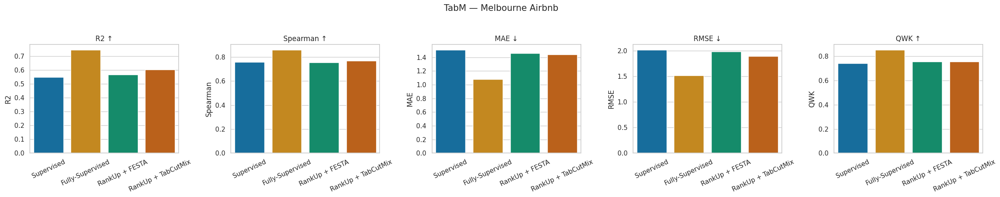

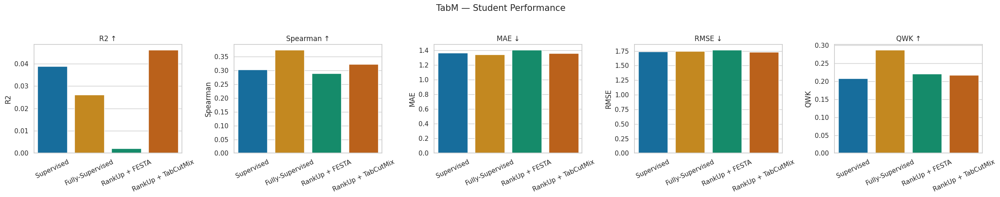

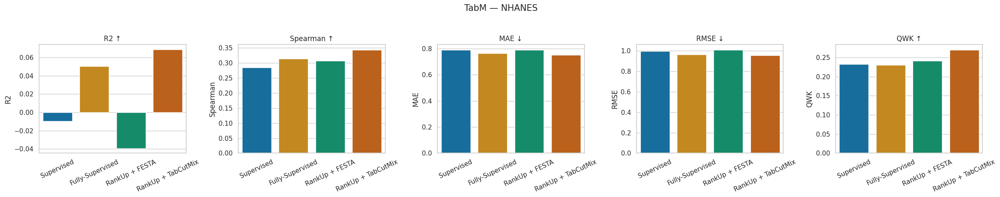

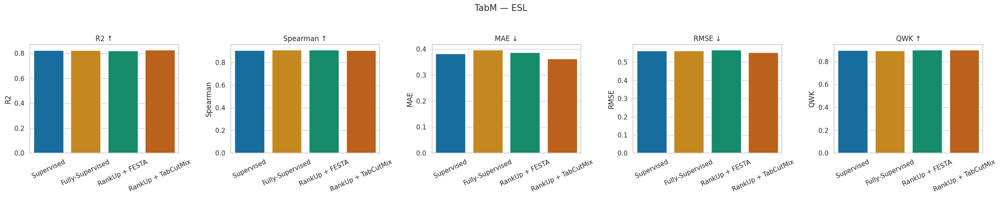

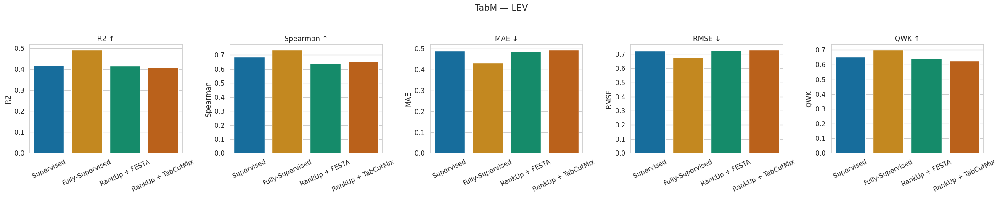

In [24]:
plot_metrics("TabM")

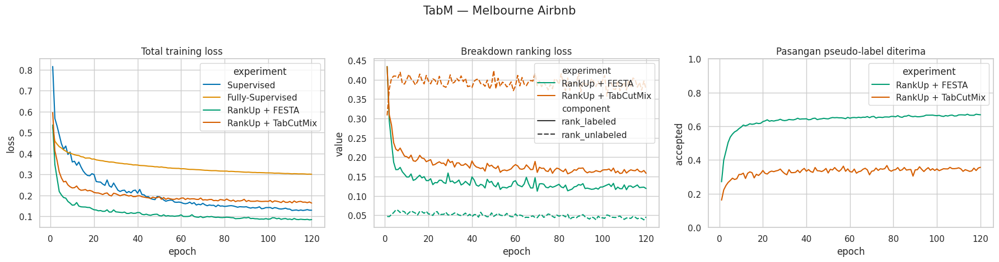

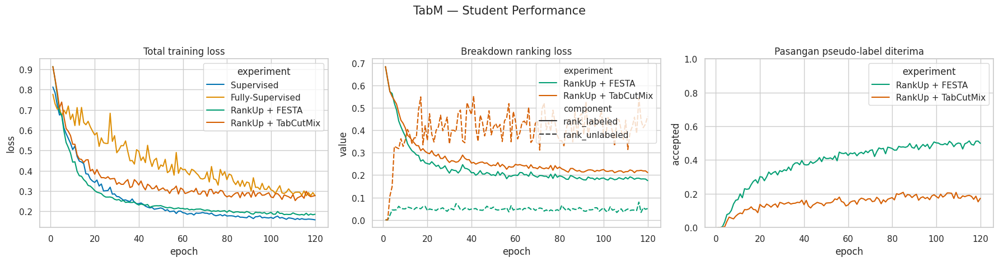

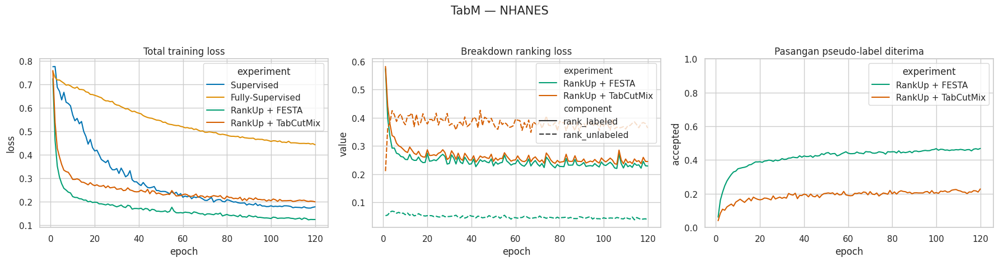

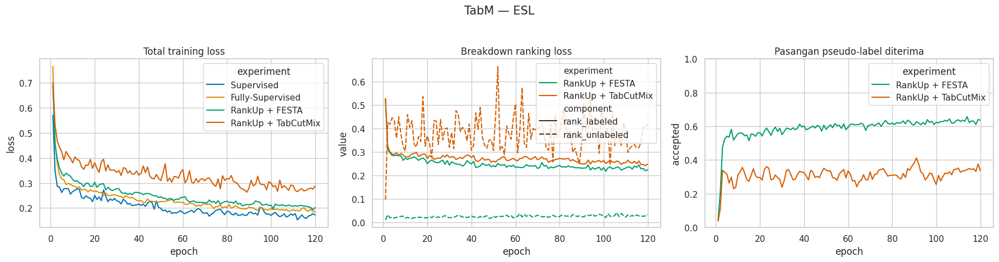

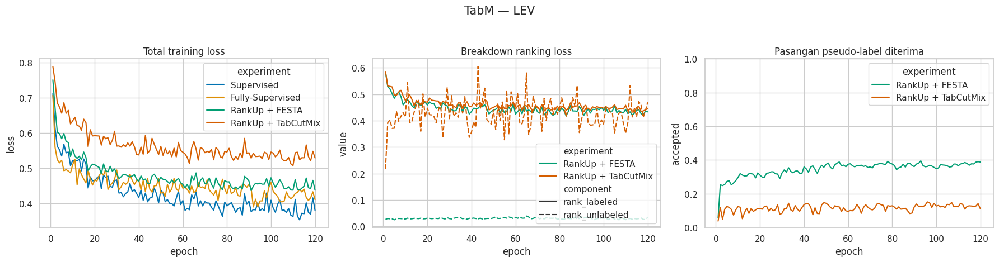

In [25]:
plot_training("TabM")

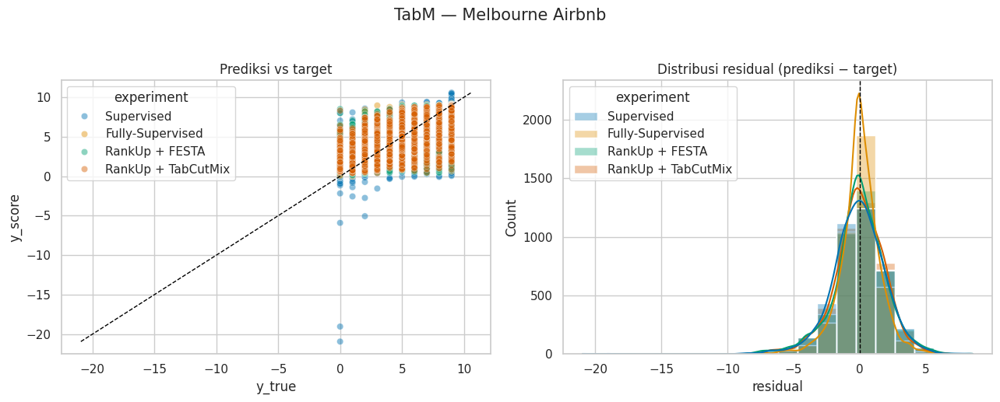

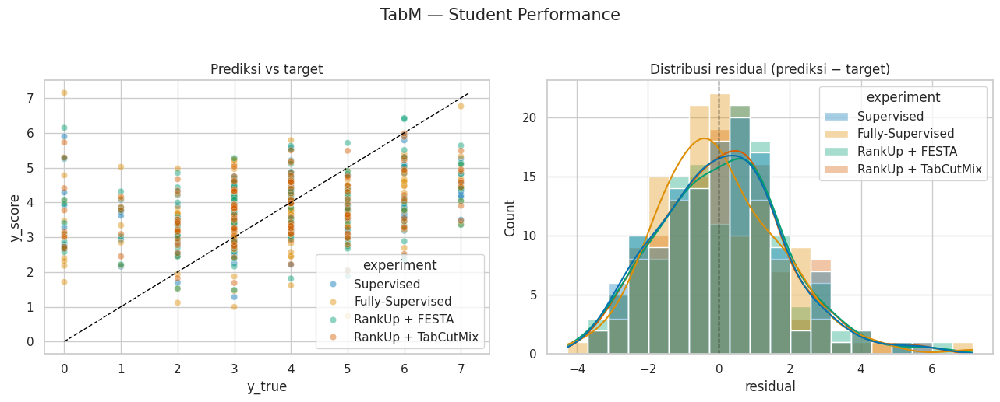

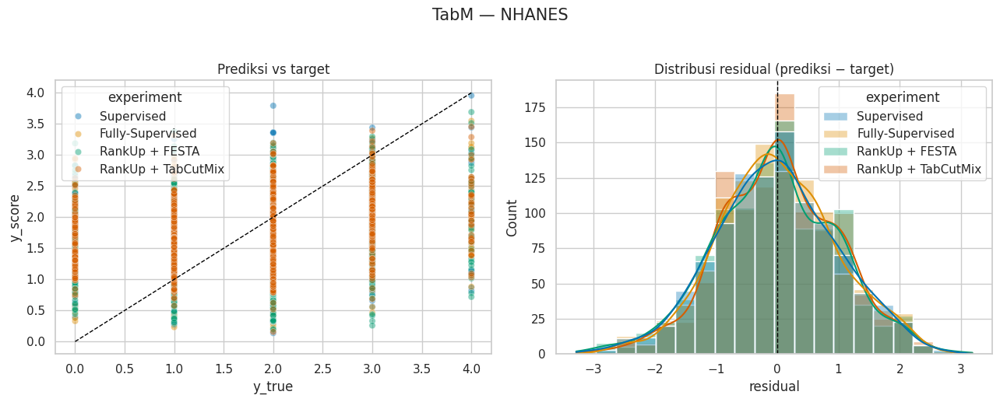

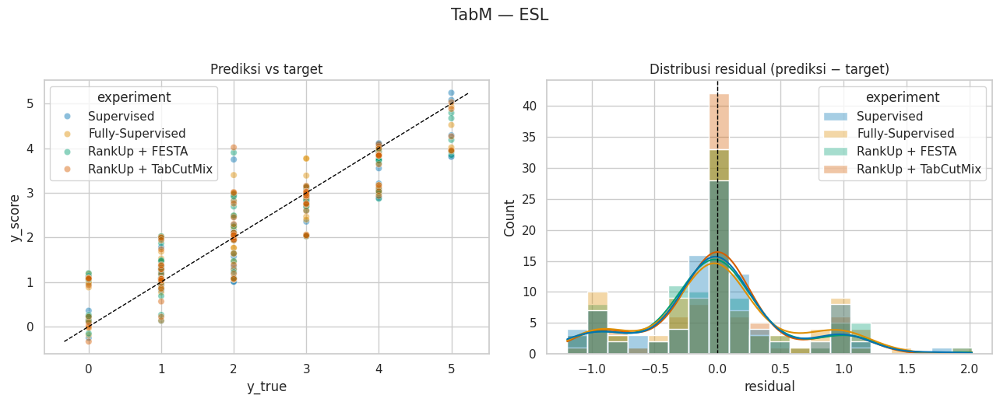

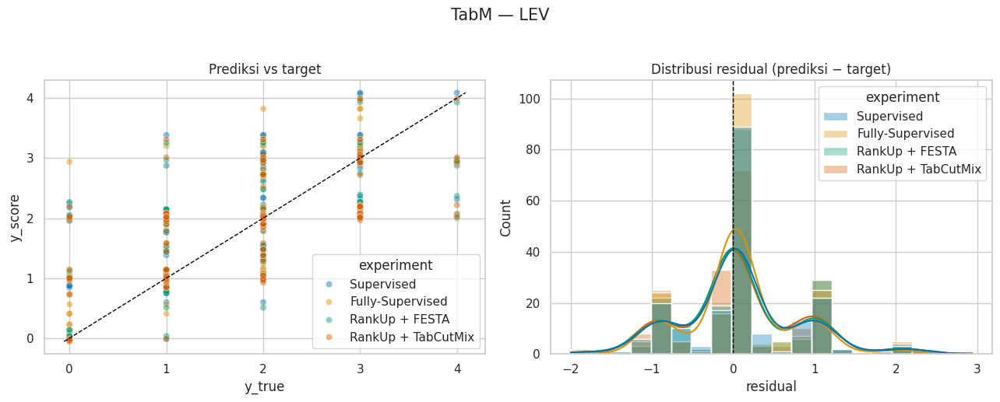

In [26]:
plot_predictions("TabM")

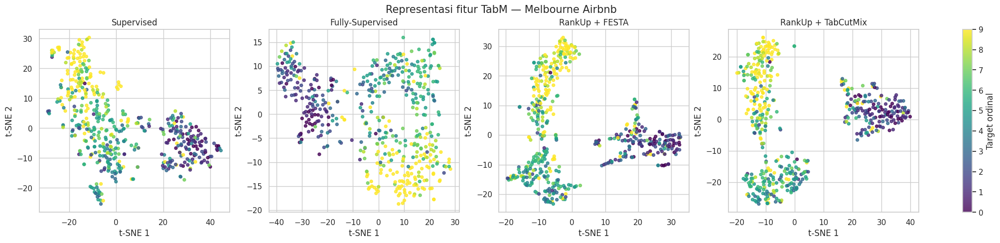

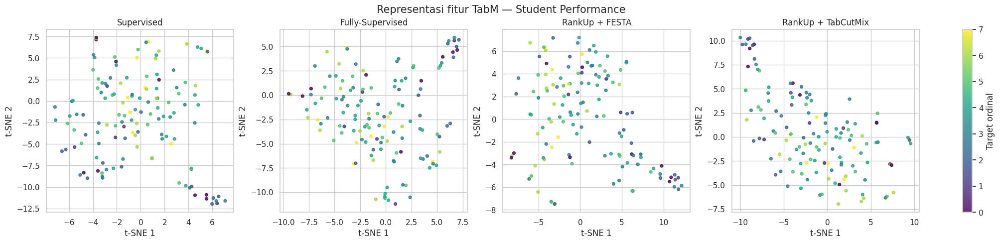

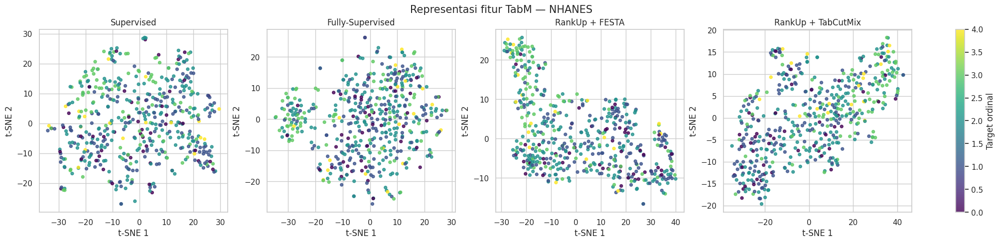

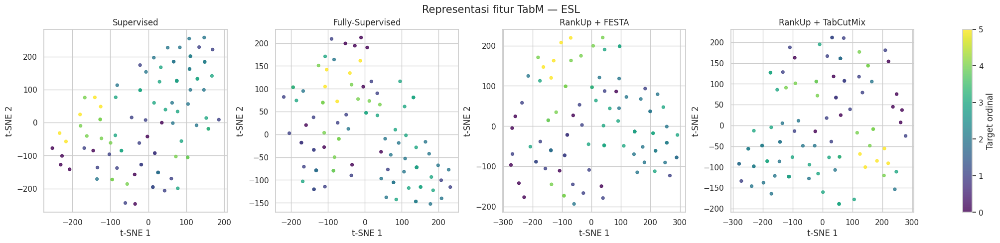

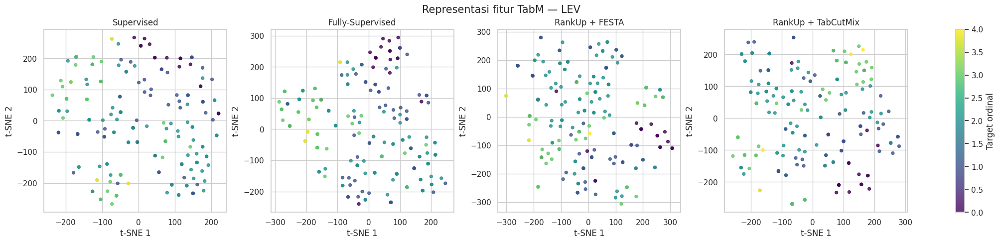

In [27]:
plot_tsne("TabM")

# 12. Eksperimen RealMLP-RankUp

Backbone mengikuti komponen RealMLP regresi: feature scaling, tiga NTPLinear 256 unit, dan Mish. Dua output head ditambahkan agar backbone yang sama dapat dipakai pada seluruh eksperimen RankUp.

## 12.1 Supervised RealMLP-RankUp

In [28]:
def train_realmlp_supervised(data):
    set_seed()
    model = RealMLP(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = make_loader(data["x_labeled"], data["y_labeled"])
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction, _ = model(x)
            loss = F.l1_loss(prediction, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        history.append({"epoch": epoch, "loss": np.mean(losses)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(losses):.4f}")
    return model, history


experiment = "Supervised"
for dataset_name, data in prepared.items():
    print(f"\nRealMLP | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_realmlp_supervised(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "RealMLP", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
realmlp_supervised = results_df.query("model == 'RealMLP' and experiment == 'Supervised'")
realmlp_supervised


RealMLP | Supervised | Melbourne Airbnb
  epoch 001/120 | loss=0.8609
  epoch 010/120 | loss=0.7547
  epoch 020/120 | loss=0.4574
  epoch 030/120 | loss=0.4005
  epoch 040/120 | loss=0.3488
  epoch 050/120 | loss=0.3143
  epoch 060/120 | loss=0.3484
  epoch 070/120 | loss=0.3295
  epoch 080/120 | loss=0.2692
  epoch 090/120 | loss=0.2413
  epoch 100/120 | loss=0.2619
  epoch 110/120 | loss=0.1905
  epoch 120/120 | loss=0.1843
{'R2': 0.5142, 'Spearman': 0.7376, 'MAE': 1.5795, 'RMSE': 2.0936, 'QWK': 0.7298}

RealMLP | Supervised | Student Performance
  epoch 001/120 | loss=0.8271
  epoch 010/120 | loss=0.7359
  epoch 020/120 | loss=0.7075
  epoch 030/120 | loss=0.6242
  epoch 040/120 | loss=0.5268
  epoch 050/120 | loss=0.5077
  epoch 060/120 | loss=0.4291
  epoch 070/120 | loss=0.3602
  epoch 080/120 | loss=0.3112
  epoch 090/120 | loss=0.2476
  epoch 100/120 | loss=0.2368
  epoch 110/120 | loss=0.2004
  epoch 120/120 | loss=0.1609
{'R2': -0.3559, 'Spearman': 0.0726, 'MAE': 1.6467, 'RM

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
40,Melbourne Airbnb,RealMLP,Supervised,42,Tesla T4,2.018817,0.018142,0.514227,0.737555,1.579475,2.093551,0.729828
41,Student Performance,RealMLP,Supervised,42,Tesla T4,1.950824,0.001730,-0.355939,0.072614,1.646725,2.064271,0.077374
42,NHANES,RealMLP,Supervised,42,Tesla T4,1.954358,0.005127,-0.149458,0.267202,0.847475,1.060399,0.238932
43,ESL,RealMLP,Supervised,42,Tesla T4,1.973408,0.001488,0.863800,0.934204,0.372470,0.494574,0.896459
44,LEV,RealMLP,Supervised,42,Tesla T4,1.929154,0.002253,0.482401,0.701314,0.491686,0.684181,0.683294


## 12.2 Fully-Supervised RealMLP-RankUp

In [29]:
def train_realmlp_fully_supervised(data):
    set_seed()
    model = RealMLP(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = make_loader(data["x_train"], data["y_train"], SUPERVISED_BATCH_SIZE)
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction, _ = model(x)
            loss = F.l1_loss(prediction, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        history.append({"epoch": epoch, "loss": np.mean(losses)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(losses):.4f}")
    return model, history


experiment = "Fully-Supervised"
for dataset_name, data in prepared.items():
    print(f"\nRealMLP | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_realmlp_fully_supervised(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "RealMLP", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
realmlp_fully = results_df.query("model == 'RealMLP' and experiment == 'Fully-Supervised'")
realmlp_fully


RealMLP | Fully-Supervised | Melbourne Airbnb
  epoch 001/120 | loss=0.8252
  epoch 010/120 | loss=0.4317
  epoch 020/120 | loss=0.4078
  epoch 030/120 | loss=0.3909
  epoch 040/120 | loss=0.3768
  epoch 050/120 | loss=0.3647
  epoch 060/120 | loss=0.3530
  epoch 070/120 | loss=0.3439
  epoch 080/120 | loss=0.3350
  epoch 090/120 | loss=0.3255
  epoch 100/120 | loss=0.3177
  epoch 110/120 | loss=0.3105
  epoch 120/120 | loss=0.3028
{'R2': 0.7035, 'Spearman': 0.839, 'MAE': 1.17, 'RMSE': 1.6356, 'QWK': 0.8368}

RealMLP | Fully-Supervised | Student Performance
  epoch 001/120 | loss=0.7872
  epoch 010/120 | loss=0.7783
  epoch 020/120 | loss=0.7495
  epoch 030/120 | loss=0.7316
  epoch 040/120 | loss=0.7914
  epoch 050/120 | loss=0.6838
  epoch 060/120 | loss=0.6803
  epoch 070/120 | loss=0.6377
  epoch 080/120 | loss=0.6108
  epoch 090/120 | loss=0.6434
  epoch 100/120 | loss=0.6564
  epoch 110/120 | loss=0.5381
  epoch 120/120 | loss=0.5617
{'R2': 0.16, 'Spearman': 0.4161, 'MAE': 1.267

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
45,Melbourne Airbnb,RealMLP,Fully-Supervised,42,Tesla T4,26.763388,0.014019,0.703495,0.839015,1.170041,1.635622,0.836845
46,Student Performance,RealMLP,Fully-Supervised,42,Tesla T4,1.107033,0.001487,0.160044,0.416093,1.267197,1.624707,0.331219
47,NHANES,RealMLP,Fully-Supervised,42,Tesla T4,6.872662,0.004696,0.080429,0.344888,0.755031,0.948453,0.271818
48,ESL,RealMLP,Fully-Supervised,42,Tesla T4,0.805193,0.002493,0.864822,0.934967,0.384936,0.492716,0.907009
49,LEV,RealMLP,Fully-Supervised,42,Tesla T4,1.546981,0.001728,0.496499,0.722703,0.477408,0.674799,0.704877


## 12.3 RankUp + FESTA RealMLP-RankUp

In [30]:
def train_realmlp_rankup_festa(data):
    set_seed()
    model = RealMLP(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    labeled_loader = make_loader(data["x_labeled"], data["y_labeled"])
    unlabeled_loader = make_loader(data["x_unlabeled"])
    edges = festa_edges(data["x_train"]).to(DEVICE)
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        totals, rank_labs, rank_unlabs, accepted = [], [], [], []
        labeled_batches = cycle(labeled_loader)
        for (x_u,) in islice(unlabeled_loader, MAX_RANKUP_STEPS):
            x_l, y_l = next(labeled_batches)
            x_l, y_l, x_u = x_l.to(DEVICE), y_l.to(DEVICE), x_u.to(DEVICE)
            weak = festa_view(x_u, edges, 0.1)
            strong = festa_view(x_u, edges, 0.3)
            optimizer.zero_grad(set_to_none=True)
            pred_l, rank_l = model(x_l)
            loss_reg = F.l1_loss(pred_l, y_l)
            loss_rank_lab = supervised_rank_loss(rank_l, y_l)
            with torch.no_grad():
                _, rank_weak = model(weak)
            _, rank_strong = model(strong)
            loss_rank_unlab, accept_rate = pseudo_rank_loss(rank_weak, rank_strong)
            loss = loss_reg + W_RANK * loss_rank_lab + W_UNLABELED * loss_rank_unlab
            loss.backward()
            optimizer.step()
            totals.append(loss.item())
            rank_labs.append(loss_rank_lab.item())
            rank_unlabs.append(loss_rank_unlab.item())
            accepted.append(accept_rate)
        history.append({"epoch": epoch, "loss": np.mean(totals), "rank_labeled": np.mean(rank_labs), "rank_unlabeled": np.mean(rank_unlabs), "accepted": np.mean(accepted)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(totals):.4f} | accepted={np.mean(accepted):.1%}")
    return model, history


experiment = "RankUp + FESTA"
for dataset_name, data in prepared.items():
    print(f"\nRealMLP | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_realmlp_rankup_festa(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "RealMLP", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
realmlp_festa = results_df.query("model == 'RealMLP' and experiment == 'RankUp + FESTA'")
realmlp_festa


RealMLP | RankUp + FESTA | Melbourne Airbnb
  epoch 001/120 | loss=0.9057 | accepted=0.5%
  epoch 010/120 | loss=0.1975 | accepted=55.7%
  epoch 020/120 | loss=0.1221 | accepted=65.8%
  epoch 030/120 | loss=0.1004 | accepted=68.6%
  epoch 040/120 | loss=0.0791 | accepted=70.8%
  epoch 050/120 | loss=0.0641 | accepted=70.9%
  epoch 060/120 | loss=0.0690 | accepted=71.0%
  epoch 070/120 | loss=0.0599 | accepted=73.5%
  epoch 080/120 | loss=0.0612 | accepted=73.7%
  epoch 090/120 | loss=0.0609 | accepted=73.5%
  epoch 100/120 | loss=0.0572 | accepted=73.9%
  epoch 110/120 | loss=0.0559 | accepted=74.3%
  epoch 120/120 | loss=0.0594 | accepted=74.6%
{'R2': 0.4411, 'Spearman': 0.7082, 'MAE': 1.702, 'RMSE': 2.2456, 'QWK': 0.7093}

RealMLP | RankUp + FESTA | Student Performance
  epoch 001/120 | loss=0.9331 | accepted=0.0%
  epoch 010/120 | loss=0.8263 | accepted=0.0%
  epoch 020/120 | loss=0.6621 | accepted=12.4%
  epoch 030/120 | loss=0.5768 | accepted=21.9%
  epoch 040/120 | loss=0.4411 |

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
50,Melbourne Airbnb,RealMLP,RankUp + FESTA,42,Tesla T4,107.866192,0.014327,0.441082,0.708155,1.702022,2.245646,0.709348
51,Student Performance,RealMLP,RankUp + FESTA,42,Tesla T4,11.736622,0.001746,-0.515145,0.096608,1.755708,2.182096,0.075998
52,NHANES,RealMLP,RankUp + FESTA,42,Tesla T4,93.274220,0.005115,-0.572434,0.195020,0.996122,1.240250,0.196333
53,ESL,RealMLP,RankUp + FESTA,42,Tesla T4,4.621053,0.001527,0.863353,0.933100,0.373440,0.495386,0.900973
54,LEV,RealMLP,RankUp + FESTA,42,Tesla T4,13.592022,0.001775,0.494267,0.715793,0.457531,0.676293,0.687307


## 12.4 RankUp + TabCutMix RealMLP-RankUp

In [31]:
def train_realmlp_rankup_tabcutmix(data):
    set_seed()
    model = RealMLP(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    labeled_loader = make_loader(data["x_labeled"], data["y_labeled"])
    unlabeled_loader = make_loader(data["x_unlabeled"])
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        totals, rank_labs, rank_unlabs, accepted = [], [], [], []
        labeled_batches = cycle(labeled_loader)
        for (x_u,) in islice(unlabeled_loader, MAX_RANKUP_STEPS):
            x_l, y_l = next(labeled_batches)
            x_l, y_l, x_u = x_l.to(DEVICE), y_l.to(DEVICE), x_u.to(DEVICE)
            weak = tabcutmix_view(x_u, 0.1)
            strong = tabcutmix_view(x_u, 0.5)
            optimizer.zero_grad(set_to_none=True)
            pred_l, rank_l = model(x_l)
            loss_reg = F.l1_loss(pred_l, y_l)
            loss_rank_lab = supervised_rank_loss(rank_l, y_l)
            with torch.no_grad():
                _, rank_weak = model(weak)
            _, rank_strong = model(strong)
            loss_rank_unlab, accept_rate = pseudo_rank_loss(rank_weak, rank_strong)
            loss = loss_reg + W_RANK * loss_rank_lab + W_UNLABELED * loss_rank_unlab
            loss.backward()
            optimizer.step()
            totals.append(loss.item())
            rank_labs.append(loss_rank_lab.item())
            rank_unlabs.append(loss_rank_unlab.item())
            accepted.append(accept_rate)
        history.append({"epoch": epoch, "loss": np.mean(totals), "rank_labeled": np.mean(rank_labs), "rank_unlabeled": np.mean(rank_unlabs), "accepted": np.mean(accepted)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(totals):.4f} | accepted={np.mean(accepted):.1%}")
    return model, history


experiment = "RankUp + TabCutMix"
for dataset_name, data in prepared.items():
    print(f"\nRealMLP | {experiment} | {dataset_name}")
    started = time.perf_counter()
    model, history = train_realmlp_rankup_tabcutmix(data)
    training_seconds = time.perf_counter() - started
    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started
    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    representations[(dataset_name, "RealMLP", experiment)] = extract_features(model, data)
    results.append({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, "seed": SEED, "hardware": HARDWARE, "training_seconds": training_seconds, "inference_seconds": inference_seconds, **metrics})
    predictions.extend({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, "row": i, "y_true": true, "y_score": pred, "residual": pred - true} for i, (true, pred) in enumerate(zip(data["y_test"], score)))
    histories.extend({"dataset": dataset_name, "model": "RealMLP", "experiment": experiment, **row} for row in history)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(histories)
results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
realmlp_tabcutmix = results_df.query("model == 'RealMLP' and experiment == 'RankUp + TabCutMix'")
realmlp_tabcutmix


RealMLP | RankUp + TabCutMix | Melbourne Airbnb
  epoch 001/120 | loss=0.9107 | accepted=0.3%
  epoch 010/120 | loss=0.2783 | accepted=28.7%
  epoch 020/120 | loss=0.2126 | accepted=30.8%
  epoch 030/120 | loss=0.1858 | accepted=32.0%
  epoch 040/120 | loss=0.1645 | accepted=31.7%
  epoch 050/120 | loss=0.1516 | accepted=32.1%
  epoch 060/120 | loss=0.1459 | accepted=32.0%
  epoch 070/120 | loss=0.1464 | accepted=34.4%
  epoch 080/120 | loss=0.1390 | accepted=34.1%
  epoch 090/120 | loss=0.1442 | accepted=33.3%
  epoch 100/120 | loss=0.1387 | accepted=34.6%
  epoch 110/120 | loss=0.1390 | accepted=35.1%
  epoch 120/120 | loss=0.1324 | accepted=36.6%
{'R2': 0.5005, 'Spearman': 0.7203, 'MAE': 1.6353, 'RMSE': 2.123, 'QWK': 0.7153}

RealMLP | RankUp + TabCutMix | Student Performance
  epoch 001/120 | loss=0.9331 | accepted=0.0%
  epoch 010/120 | loss=0.8263 | accepted=0.0%
  epoch 020/120 | loss=0.7230 | accepted=7.6%
  epoch 030/120 | loss=0.6599 | accepted=11.2%
  epoch 040/120 | loss=0

,dataset,model,experiment,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
55,Melbourne Airbnb,RealMLP,RankUp + TabCutMix,42,Tesla T4,65.334064,0.018160,0.500473,0.720346,1.635302,2.122984,0.715343
56,Student Performance,RealMLP,RankUp + TabCutMix,42,Tesla T4,7.459906,0.001582,-0.427469,0.106837,1.704587,2.118020,0.090603
57,NHANES,RealMLP,RankUp + TabCutMix,42,Tesla T4,64.971056,0.004712,-0.253643,0.265134,0.883618,1.107414,0.240365
58,ESL,RealMLP,RankUp + TabCutMix,42,Tesla T4,4.128878,0.001703,0.866200,0.935202,0.372809,0.490198,0.900973
59,LEV,RealMLP,RankUp + TabCutMix,42,Tesla T4,12.624278,0.001744,0.504311,0.717953,0.451832,0.669544,0.681275


## 12.5 Hasil dan visualisasi RealMLP-RankUp

In [32]:
show_model_summary("RealMLP")

,dataset,experiment,R2,Spearman,MAE,RMSE,QWK,training_seconds,inference_seconds
0,Melbourne Airbnb,Supervised,0.5142,0.7376,1.5795,2.0936,0.7298,2.0,0.018
1,Student Performance,Supervised,-0.3559,0.0726,1.6467,2.0643,0.0774,2.0,0.002
2,NHANES,Supervised,-0.1495,0.2672,0.8475,1.0604,0.2389,2.0,0.005
3,ESL,Supervised,0.8638,0.9342,0.3725,0.4946,0.8965,2.0,0.001
4,LEV,Supervised,0.4824,0.7013,0.4917,0.6842,0.6833,1.9,0.002
5,Melbourne Airbnb,Fully-Supervised,0.7035,0.8390,1.1700,1.6356,0.8368,26.8,0.014
6,Student Performance,Fully-Supervised,0.1600,0.4161,1.2672,1.6247,0.3312,1.1,0.001
7,NHANES,Fully-Supervised,0.0804,0.3449,0.7550,0.9485,0.2718,6.9,0.005
8,ESL,Fully-Supervised,0.8648,0.9350,0.3849,0.4927,0.9070,0.8,0.002
9,LEV,Fully-Supervised,0.4965,0.7227,0.4774,0.6748,0.7049,1.5,0.002


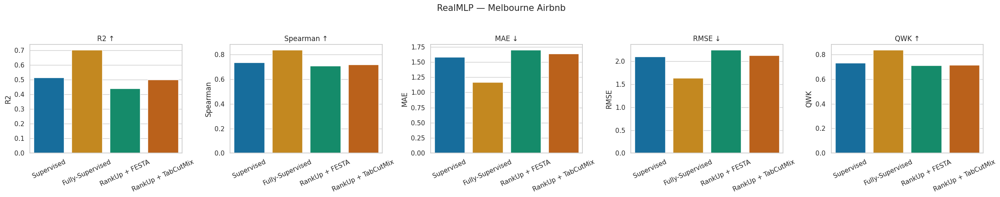

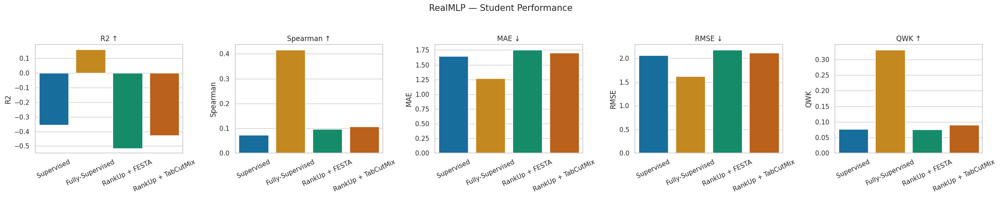

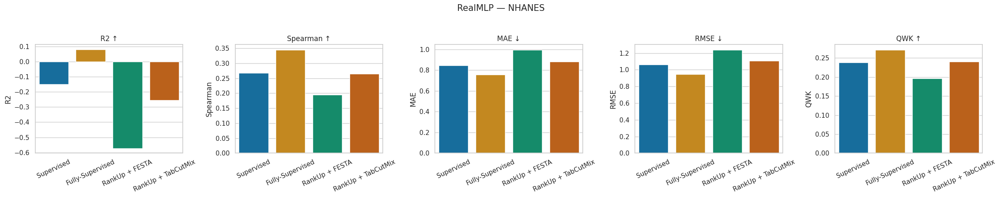

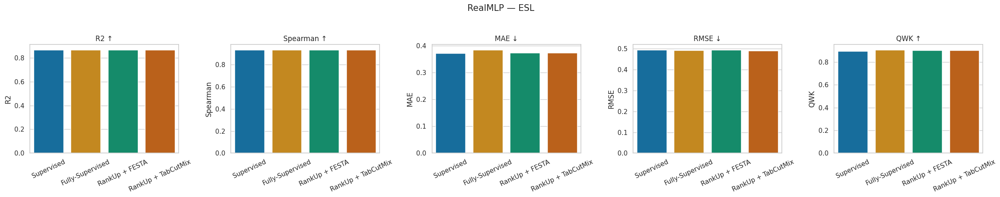

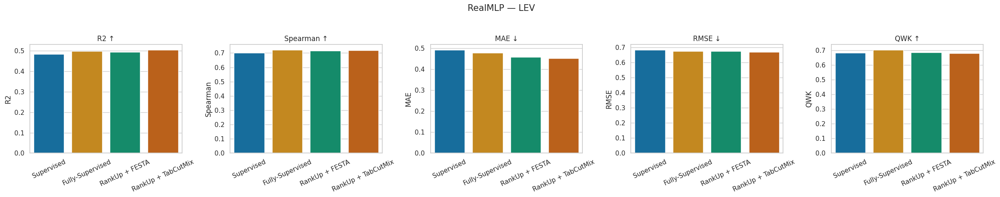

In [33]:
plot_metrics("RealMLP")

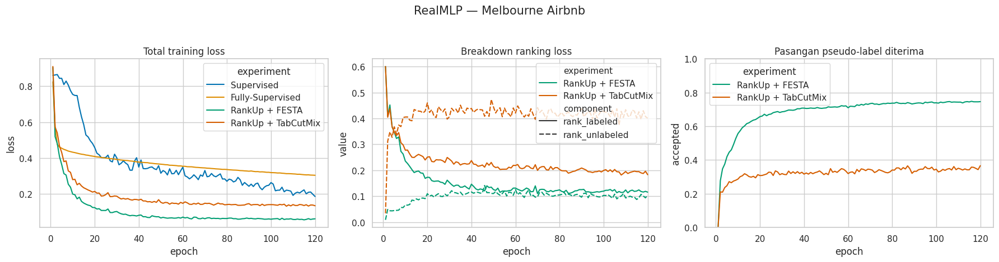

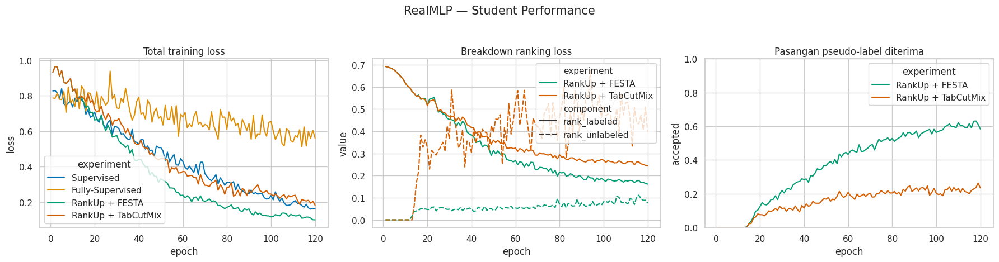

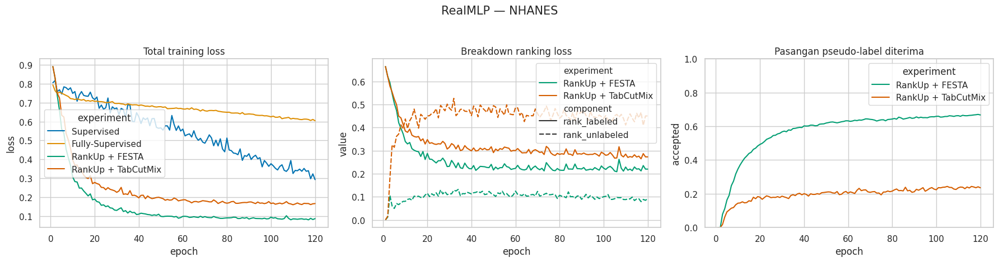

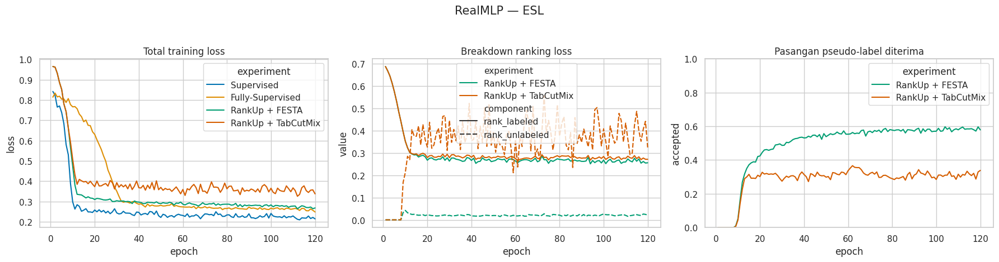

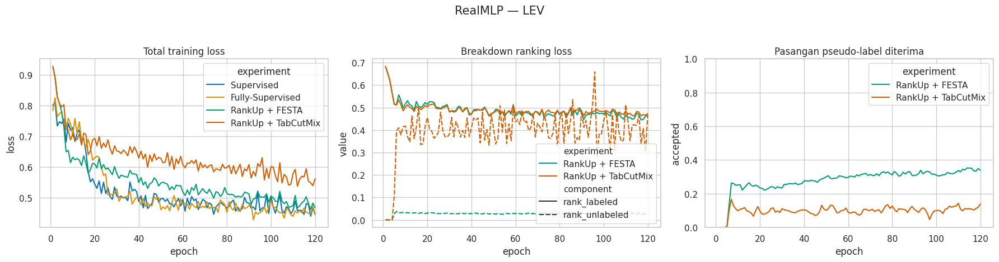

In [34]:
plot_training("RealMLP")

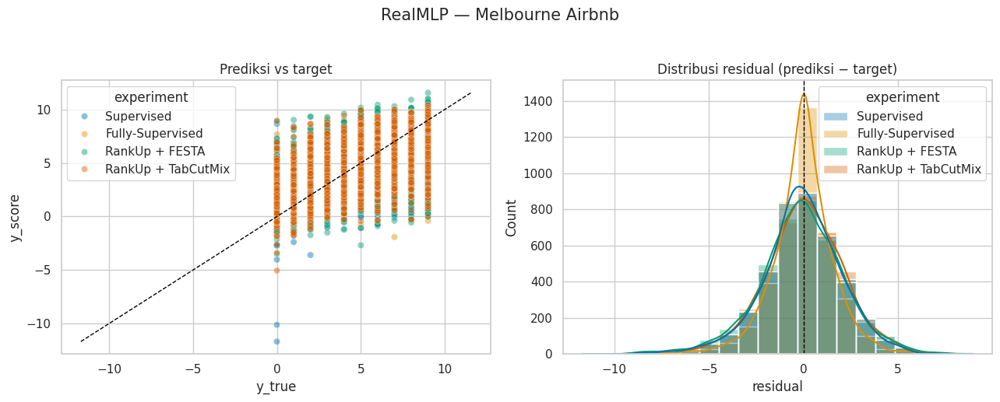

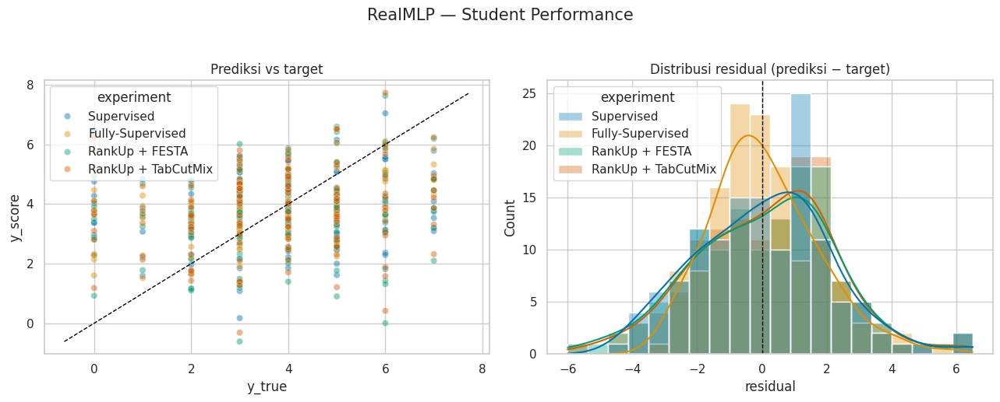

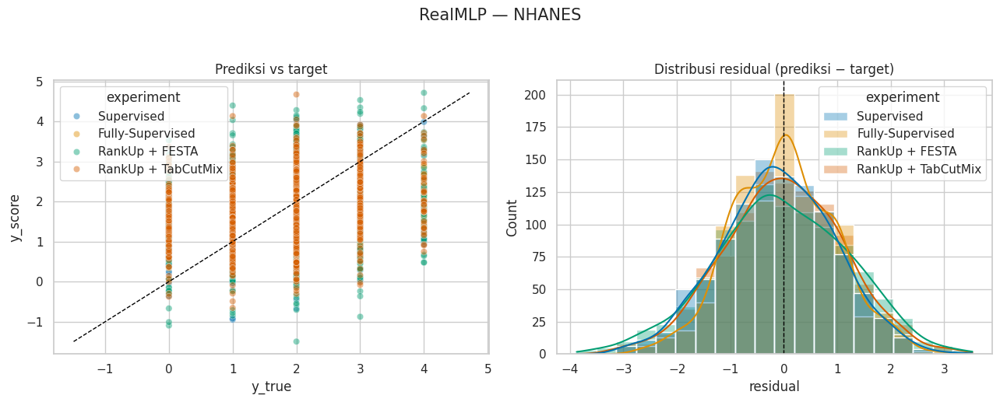

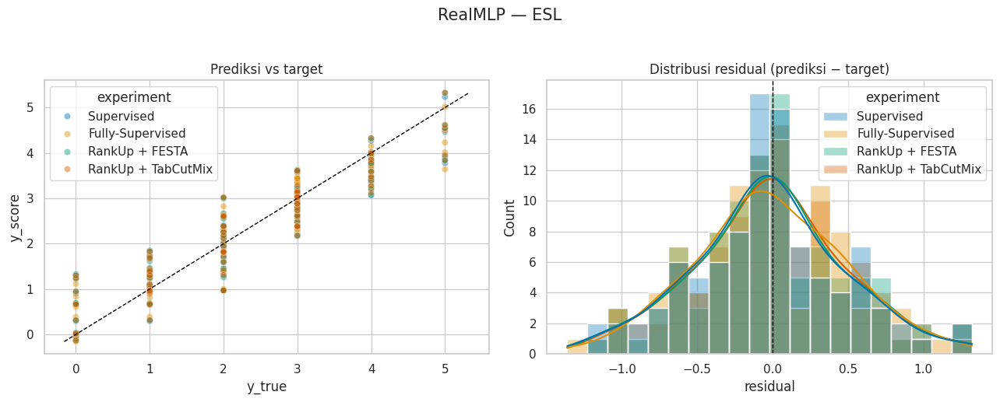

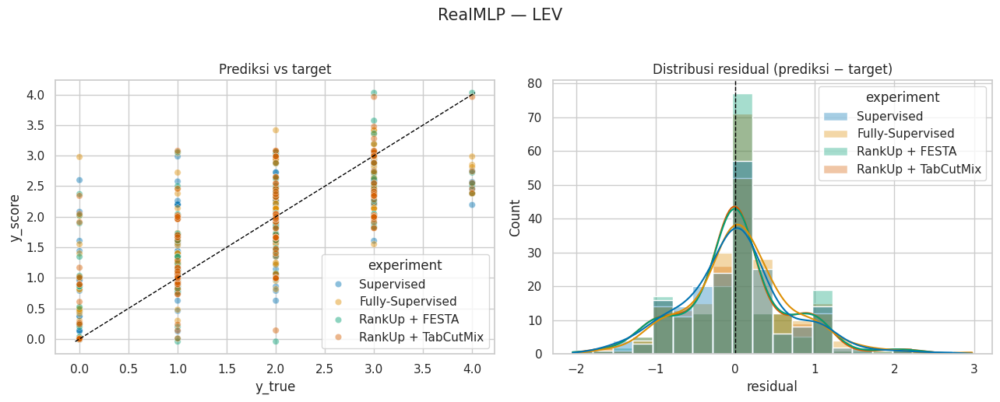

In [35]:
plot_predictions("RealMLP")

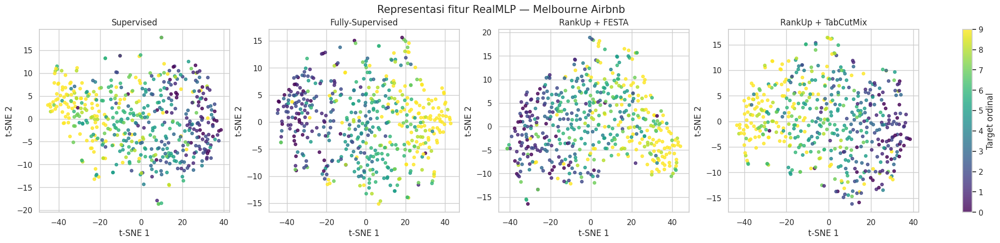

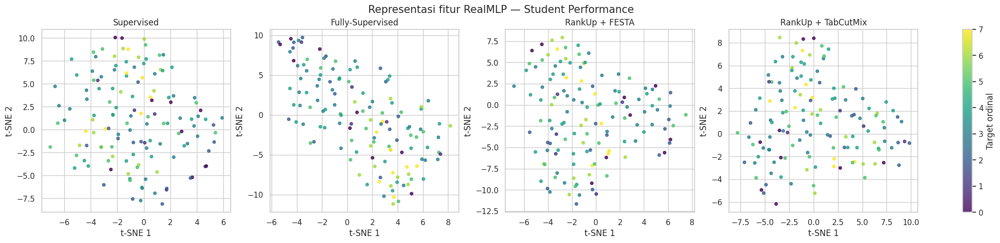

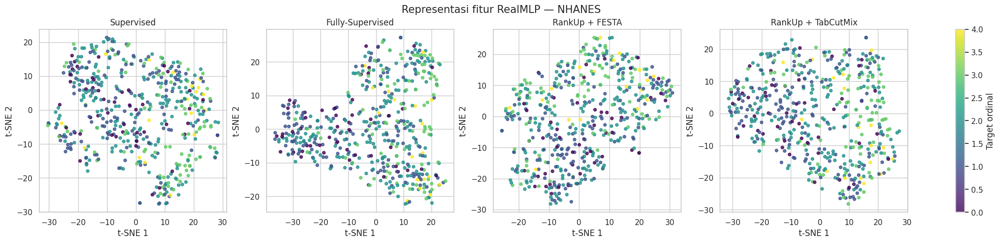

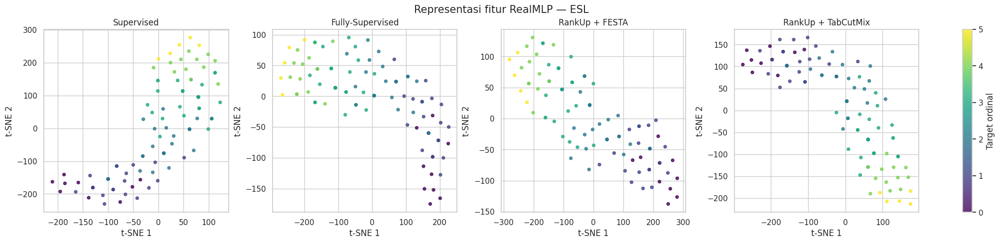

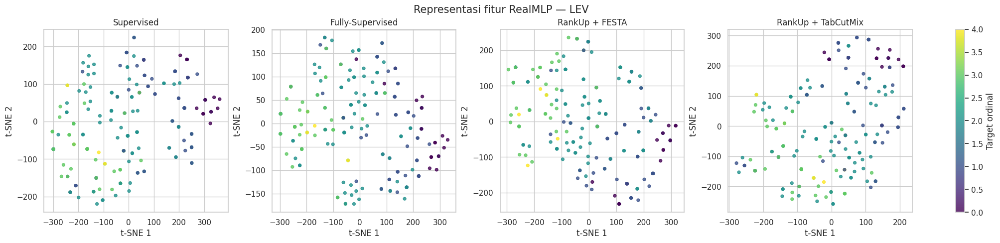

In [36]:
plot_tsne("RealMLP")

# 13. Perbandingan akhir seluruh model

In [37]:
comparison_columns = [
    "model", "experiment", "R2", "Spearman", "MAE", "RMSE", "QWK",
    "training_seconds", "inference_seconds",
]

for dataset_name in DATASET_FILES:
    table = results_df[results_df["dataset"] == dataset_name][comparison_columns].copy()
    table["model"] = pd.Categorical(table["model"], MODELS, ordered=True)
    table["experiment"] = pd.Categorical(table["experiment"], EXPERIMENTS, ordered=True)
    table = table.sort_values(["model", "experiment"]).reset_index(drop=True)
    styled = (
        table.style
        .set_caption(dataset_name)
        .format({
            **{metric: "{:.4f}" for metric in METRICS},
            "training_seconds": "{:.1f}",
            "inference_seconds": "{:.3f}",
        })
        .highlight_max(subset=["R2", "Spearman", "QWK"], color="#c6efce")
        .highlight_min(subset=["MAE", "RMSE"], color="#c6efce")
        .set_properties(subset=["model", "experiment"], **{"text-align": "left"})
    )
    display(styled)

,model,experiment,R2,Spearman,MAE,RMSE,QWK,training_seconds,inference_seconds
0,MLP,Supervised,0.3074,0.6979,1.7716,2.4998,0.6926,7.7,0.018
1,MLP,Fully-Supervised,0.6894,0.8289,1.2120,1.6739,0.8268,22.2,0.013
2,MLP,RankUp + FESTA,0.1333,0.6799,1.8667,2.7964,0.6824,93.4,0.013
3,MLP,RankUp + TabCutMix,0.5107,0.7220,1.6374,2.1011,0.6998,50.2,0.013
4,TabM,Supervised,0.5489,0.7559,1.5092,2.0175,0.7428,2.8,0.068
5,TabM,Fully-Supervised,0.7450,0.8595,1.0801,1.5168,0.8538,107.0,0.069
6,TabM,RankUp + FESTA,0.5648,0.7552,1.4585,1.9817,0.7567,132.0,0.068
7,TabM,RankUp + TabCutMix,0.6024,0.7668,1.4423,1.8941,0.7547,89.4,0.068
8,RealMLP,Supervised,0.5142,0.7376,1.5795,2.0936,0.7298,2.0,0.018
9,RealMLP,Fully-Supervised,0.7035,0.8390,1.1700,1.6356,0.8368,26.8,0.014


,model,experiment,R2,Spearman,MAE,RMSE,QWK,training_seconds,inference_seconds
0,MLP,Supervised,-0.4009,0.1513,1.6784,2.0982,0.0963,1.5,0.002
1,MLP,Fully-Supervised,-0.1643,0.2424,1.4591,1.9128,0.2027,0.9,0.001
2,MLP,RankUp + FESTA,-0.6085,0.1310,1.7751,2.2483,0.1144,9.9,0.001
3,MLP,RankUp + TabCutMix,-0.3482,0.1751,1.6506,2.0584,0.1739,5.8,0.002
4,TabM,Supervised,0.0389,0.3021,1.3670,1.7379,0.2079,2.7,0.003
5,TabM,Fully-Supervised,0.0261,0.3741,1.3426,1.7495,0.2871,3.8,0.004
6,TabM,RankUp + FESTA,0.0021,0.2893,1.4069,1.7709,0.2207,14.2,0.003
7,TabM,RankUp + TabCutMix,0.0462,0.3222,1.3620,1.7313,0.2168,10.2,0.003
8,RealMLP,Supervised,-0.3559,0.0726,1.6467,2.0643,0.0774,2.0,0.002
9,RealMLP,Fully-Supervised,0.1600,0.4161,1.2672,1.6247,0.3312,1.1,0.001


,model,experiment,R2,Spearman,MAE,RMSE,QWK,training_seconds,inference_seconds
0,MLP,Supervised,-0.3238,0.2388,0.8920,1.1380,0.2035,1.5,0.004
1,MLP,Fully-Supervised,-0.0075,0.2942,0.7862,0.9928,0.2589,5.7,0.004
2,MLP,RankUp + FESTA,-0.4448,0.2575,0.9370,1.1889,0.2208,77.6,0.004
3,MLP,RankUp + TabCutMix,-0.1208,0.3154,0.8337,1.0471,0.2621,49.7,0.004
4,TabM,Supervised,-0.0095,0.2843,0.7888,0.9937,0.2323,2.7,0.017
5,TabM,Fully-Supervised,0.0507,0.3135,0.7641,0.9637,0.2308,27.4,0.019
6,TabM,RankUp + FESTA,-0.0393,0.3070,0.7901,1.0083,0.2417,117.1,0.017
7,TabM,RankUp + TabCutMix,0.0688,0.3433,0.7512,0.9544,0.2702,88.9,0.017
8,RealMLP,Supervised,-0.1495,0.2672,0.8475,1.0604,0.2389,2.0,0.005
9,RealMLP,Fully-Supervised,0.0804,0.3449,0.7550,0.9485,0.2718,6.9,0.005


,model,experiment,R2,Spearman,MAE,RMSE,QWK,training_seconds,inference_seconds
0,MLP,Supervised,0.8588,0.9252,0.3665,0.5035,0.9071,1.5,0.001
1,MLP,Fully-Supervised,0.8546,0.9293,0.3916,0.5109,0.8987,0.6,0.001
2,MLP,RankUp + FESTA,0.8590,0.9265,0.3667,0.5032,0.9006,3.6,0.001
3,MLP,RankUp + TabCutMix,0.8609,0.9275,0.3649,0.4998,0.9042,3.2,0.001
4,TabM,Supervised,0.8239,0.9075,0.3820,0.5624,0.8991,2.6,0.003
5,TabM,Fully-Supervised,0.8228,0.9103,0.3973,0.5641,0.8924,2.6,0.003
6,TabM,RankUp + FESTA,0.8200,0.9106,0.3879,0.5686,0.9024,6.0,0.003
7,TabM,RankUp + TabCutMix,0.8288,0.9056,0.3628,0.5545,0.9024,5.7,0.003
8,RealMLP,Supervised,0.8638,0.9342,0.3725,0.4946,0.8965,2.0,0.001
9,RealMLP,Fully-Supervised,0.8648,0.9350,0.3849,0.4927,0.9070,0.8,0.002


,model,experiment,R2,Spearman,MAE,RMSE,QWK,training_seconds,inference_seconds
0,MLP,Supervised,0.5051,0.7059,0.4669,0.6690,0.6653,1.5,0.002
1,MLP,Fully-Supervised,0.5180,0.7351,0.4368,0.6602,0.7074,1.3,0.001
2,MLP,RankUp + FESTA,0.4637,0.7089,0.4654,0.6964,0.6957,10.8,0.002
3,MLP,RankUp + TabCutMix,0.5051,0.7130,0.4476,0.6690,0.6693,9.8,0.002
4,TabM,Supervised,0.4196,0.6863,0.4894,0.7245,0.6535,2.6,0.004
5,TabM,Fully-Supervised,0.4932,0.7382,0.4314,0.6770,0.7015,5.3,0.004
6,TabM,RankUp + FESTA,0.4156,0.6409,0.4856,0.7270,0.6431,18.3,0.004
7,TabM,RankUp + TabCutMix,0.4076,0.6520,0.4941,0.7319,0.6275,17.5,0.004
8,RealMLP,Supervised,0.4824,0.7013,0.4917,0.6842,0.6833,1.9,0.002
9,RealMLP,Fully-Supervised,0.4965,0.7227,0.4774,0.6748,0.7049,1.5,0.002


## 13.1 Perbandingan metrik

Kelima metrik mendapat subplot sendiri karena skala dan arah optimumnya berbeda. Layout 2×3 memberi ruang untuk label model dan satu legenda bersama.

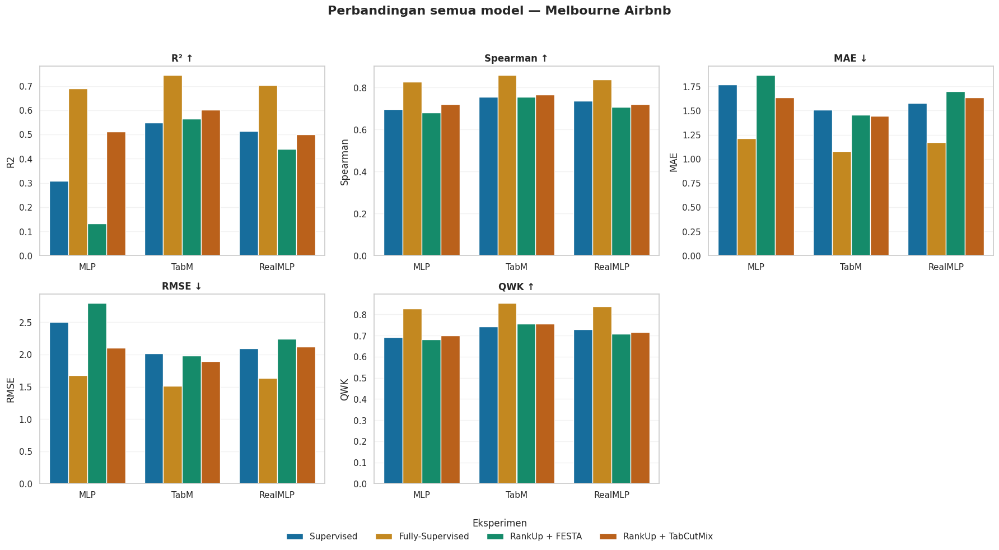

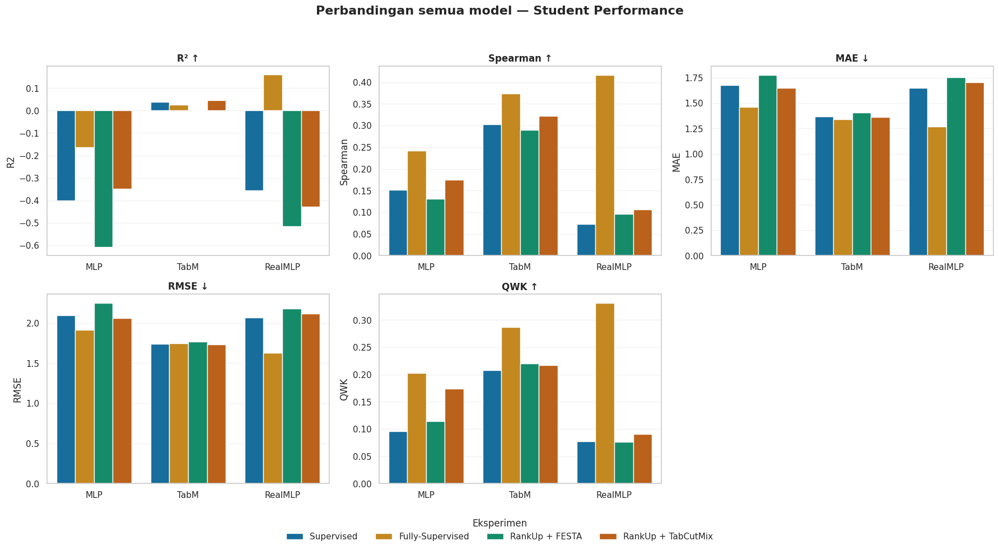

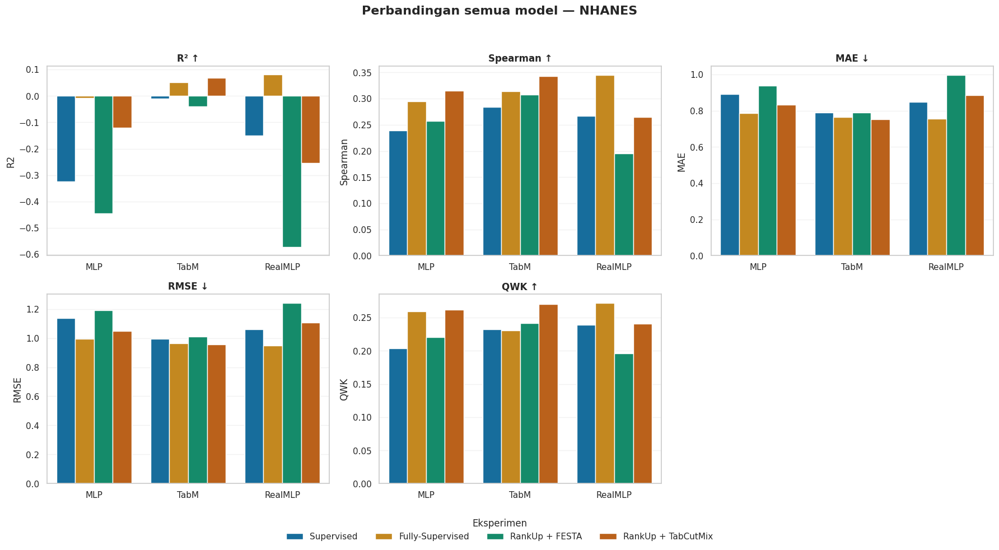

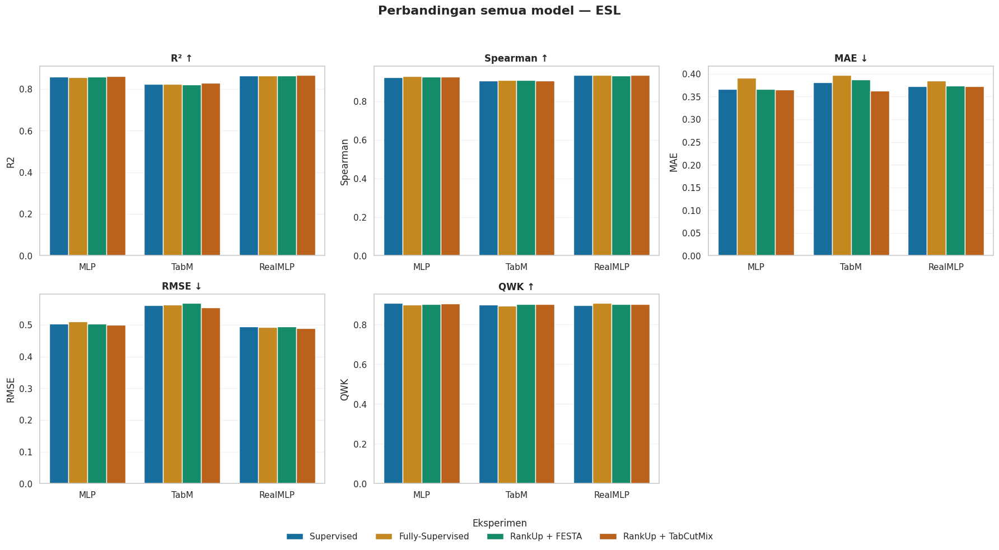

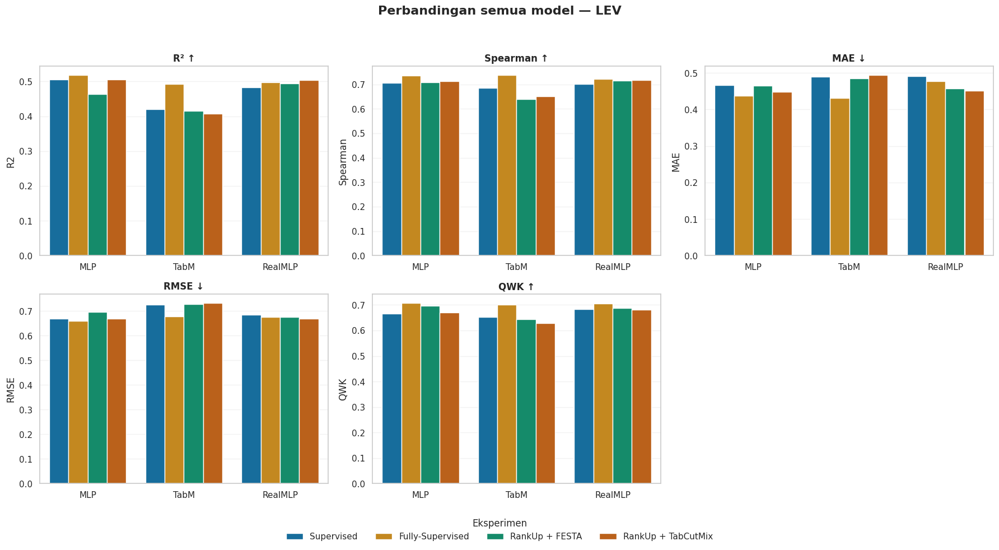

In [38]:
metric_titles = {
    "R2": "R² ↑", "Spearman": "Spearman ↑", "MAE": "MAE ↓",
    "RMSE": "RMSE ↓", "QWK": "QWK ↑",
}

for dataset_name in DATASET_FILES:
    subset = results_df[results_df["dataset"] == dataset_name]
    figure, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()

    for axis, metric in zip(axes, METRICS):
        sns.barplot(
            data=subset, x="model", y=metric, hue="experiment",
            order=MODELS, hue_order=EXPERIMENTS, palette=PALETTE, ax=axis,
        )
        axis.set_title(metric_titles[metric], fontweight="bold")
        axis.set_xlabel("")
        axis.set_ylabel(metric)
        axis.grid(axis="y", alpha=0.25)
        axis.get_legend().remove()

    axes[-1].axis("off")
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(
        handles, labels, title="Eksperimen", loc="lower center",
        bbox_to_anchor=(0.5, 0.01), ncol=4, frameon=False,
    )
    figure.suptitle(f"Perbandingan semua model — {dataset_name}", fontsize=16, fontweight="bold")
    figure.tight_layout(rect=(0, 0.08, 1, 0.95))
    filename = DATASET_FILES[dataset_name][:-4]
    figure.savefig(OUTPUT_DIR / f"comparison_metrics_{filename}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 13.2 Perbandingan kurva training

Kurva loss membantu mendeteksi training yang belum konvergen atau tidak stabil. Loss hanya boleh dibandingkan dalam model yang sama.

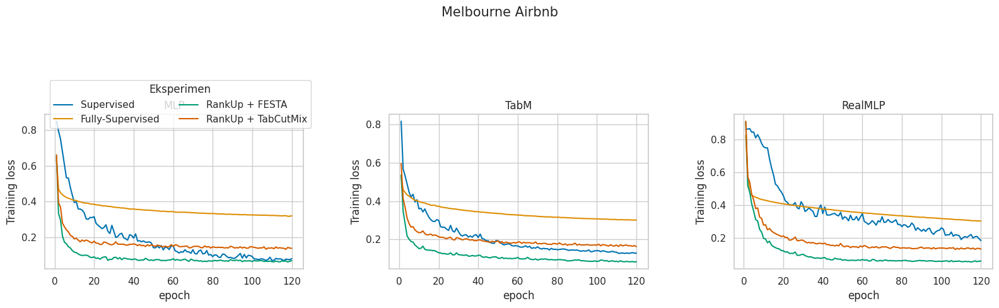

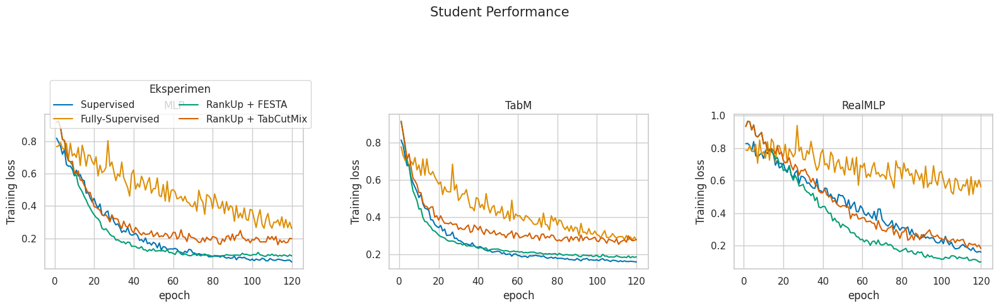

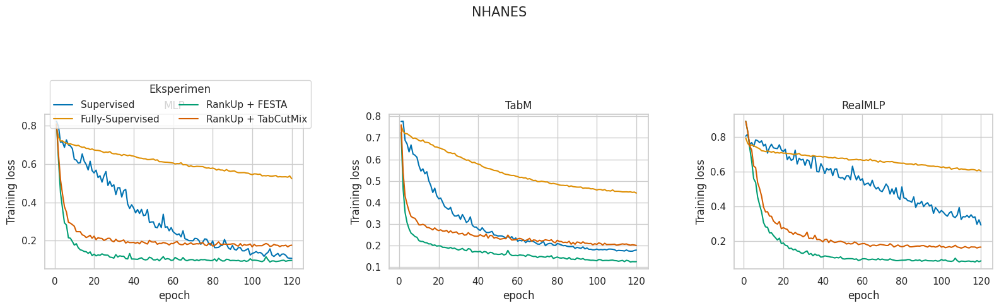

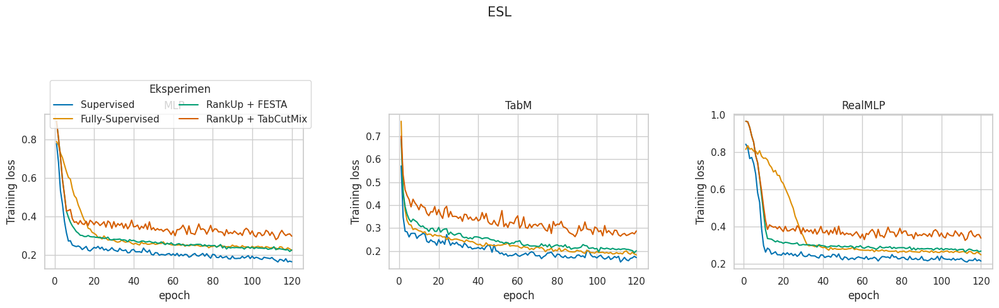

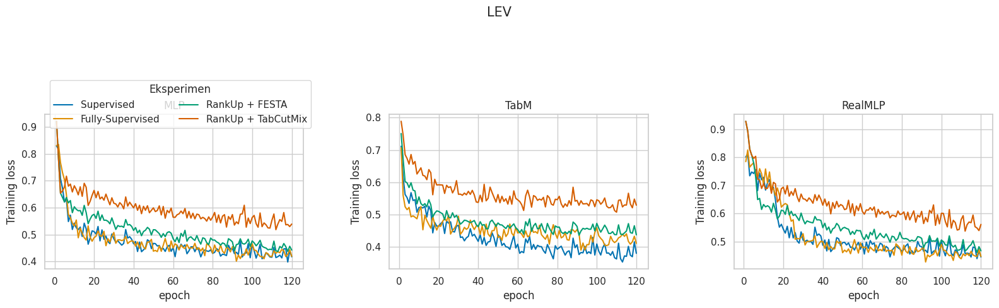

In [39]:
for dataset_name in DATASET_FILES:
    subset = history_df[history_df["dataset"] == dataset_name]
    figure, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
    for axis, model_name in zip(axes, MODELS):
        sns.lineplot(
            data=subset[subset["model"] == model_name], x="epoch", y="loss",
            hue="experiment", hue_order=EXPERIMENTS, palette=PALETTE, ax=axis,
        )
        axis.set_title(model_name)
        axis.set_ylabel("Training loss")
        if axis is not axes[0]:
            axis.get_legend().remove()
    axes[0].legend(title="Eksperimen", bbox_to_anchor=(0, 1.25), loc="upper left", ncol=2)
    figure.suptitle(dataset_name, y=1.08, fontsize=15)
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / f"loss_{DATASET_FILES[dataset_name][:-4]}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 13.3 Perbandingan prediksi dan residual

Scatter menunjukkan kedekatan skor kontinu dengan garis ideal. Distribusi residual menunjukkan bias dan sebaran error.

/tmp/ipykernel_24/3635454709.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  grid = sns.relplot(


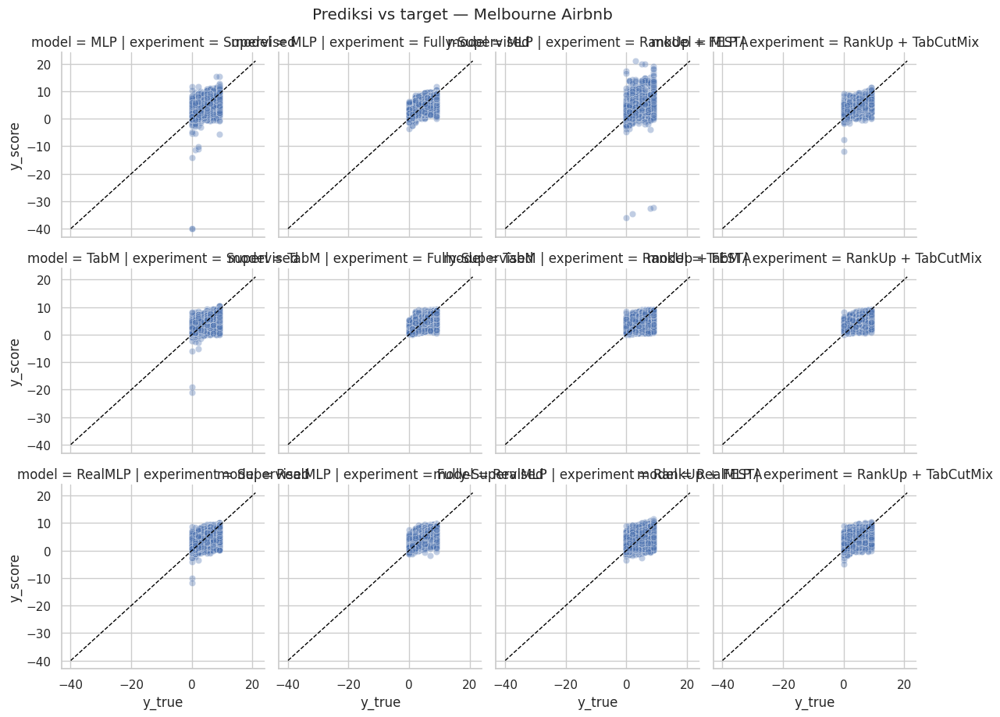

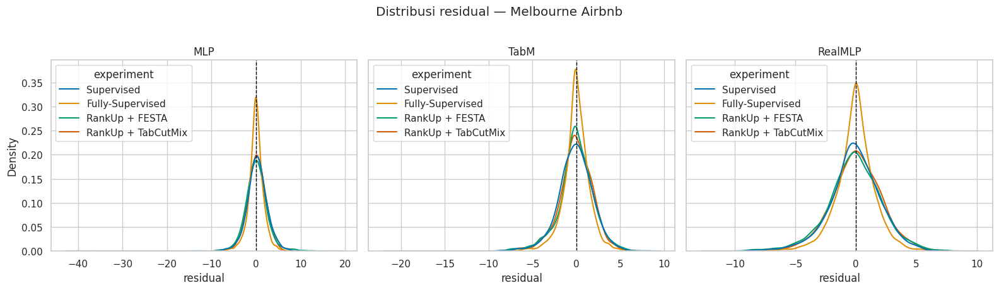

/tmp/ipykernel_24/3635454709.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  grid = sns.relplot(


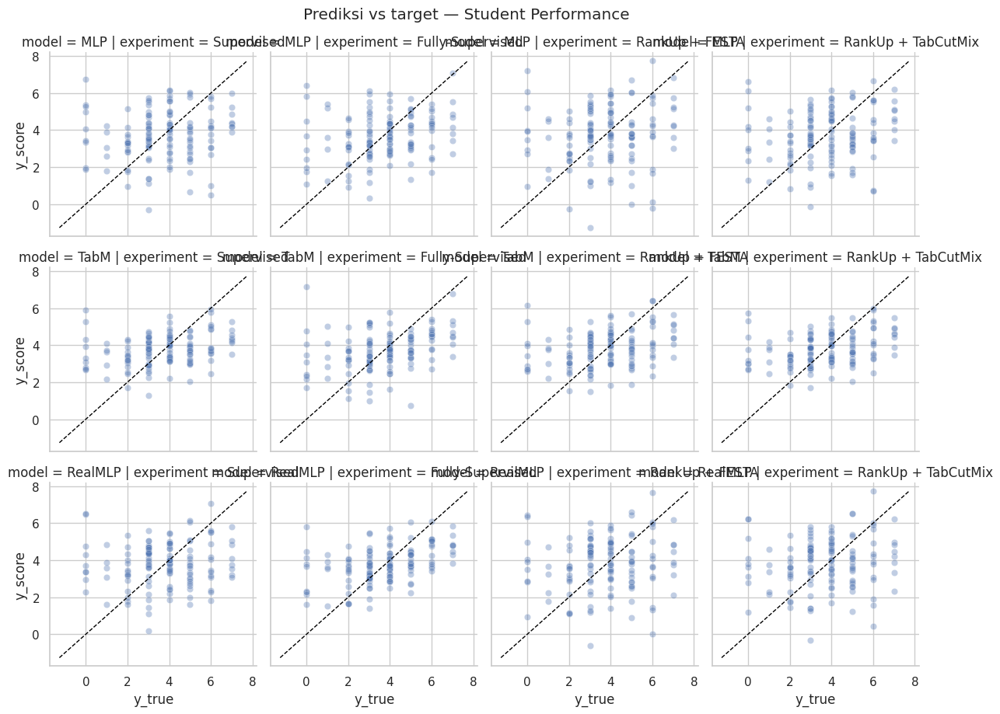

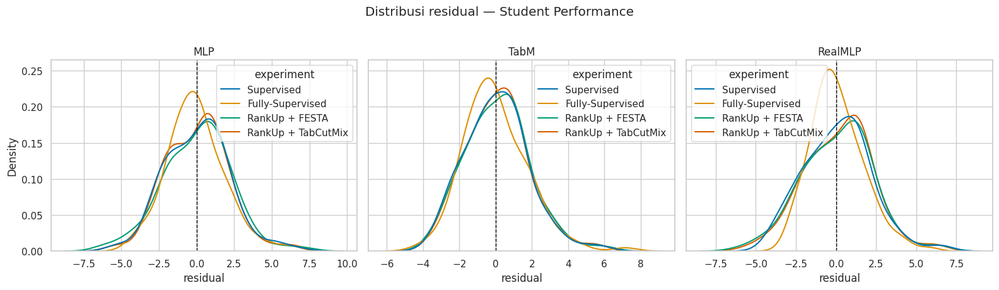

/tmp/ipykernel_24/3635454709.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  grid = sns.relplot(


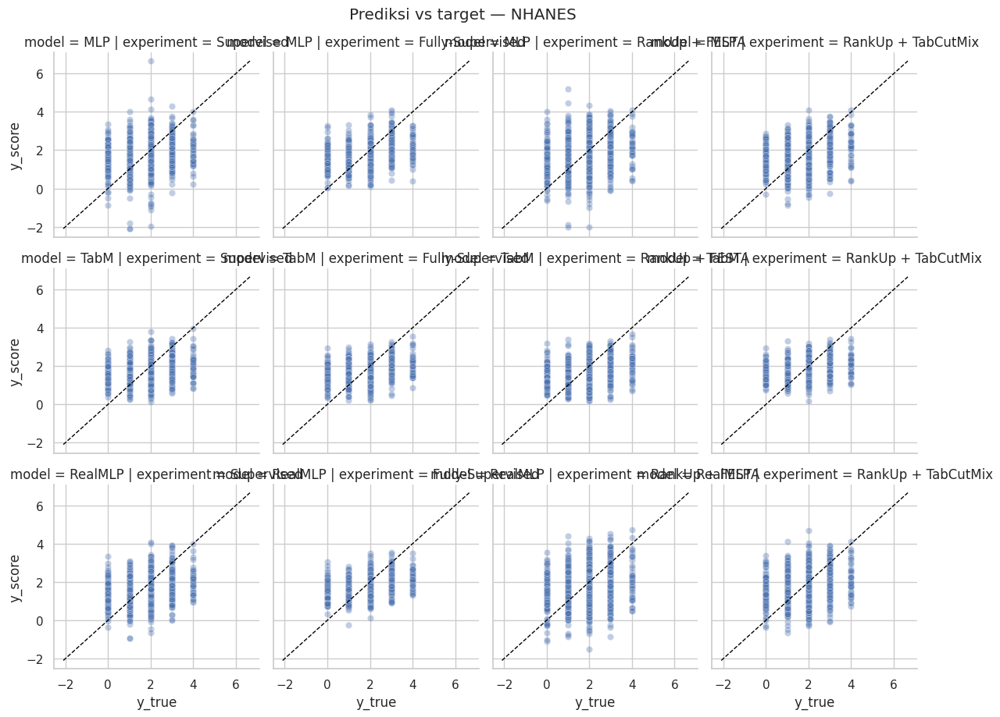

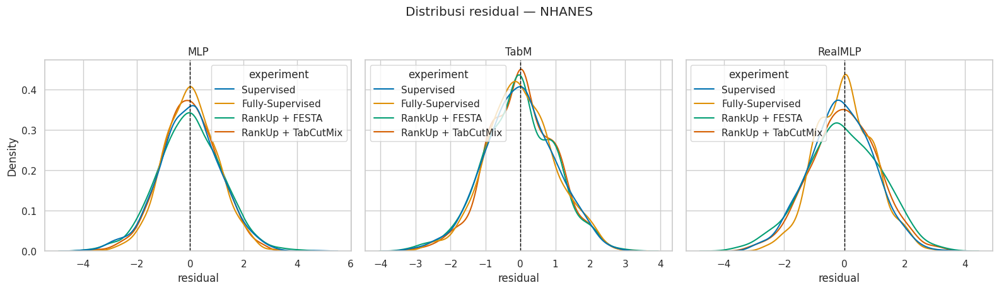

/tmp/ipykernel_24/3635454709.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  grid = sns.relplot(


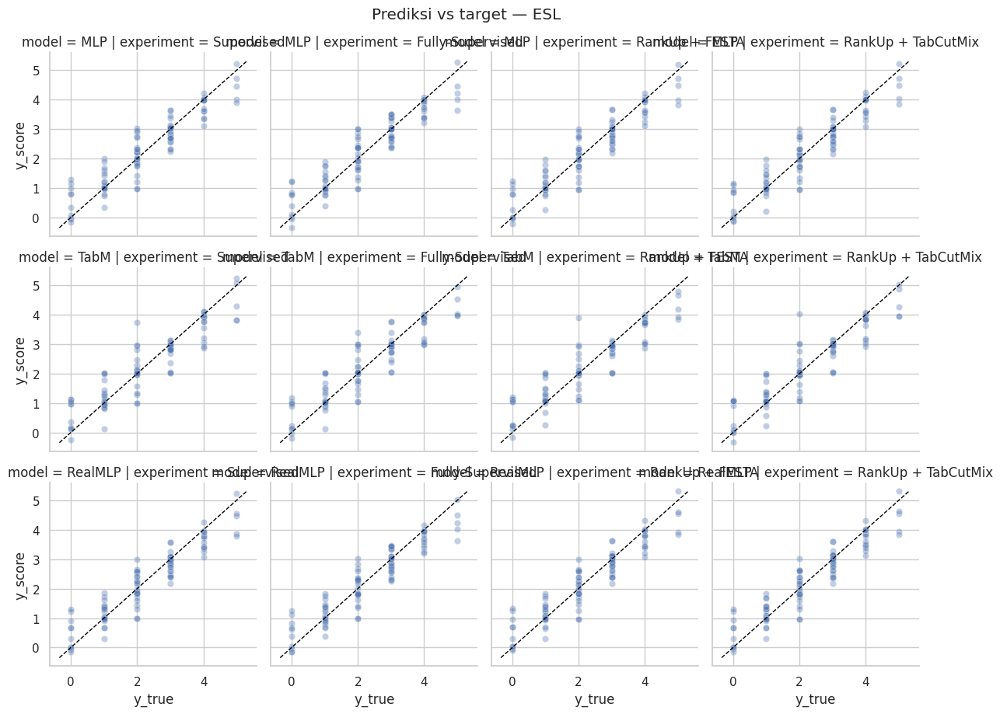

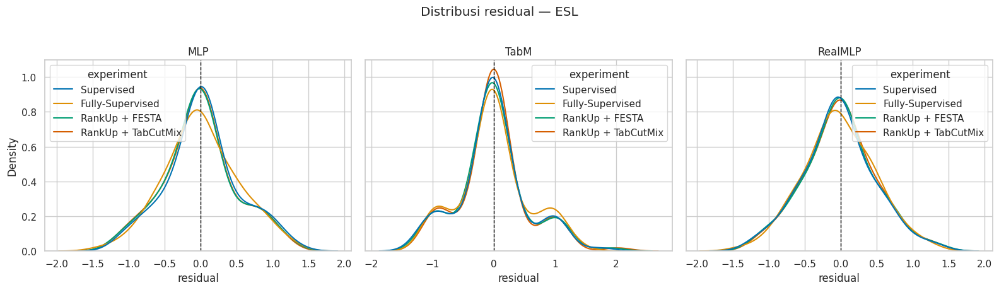

/tmp/ipykernel_24/3635454709.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  grid = sns.relplot(


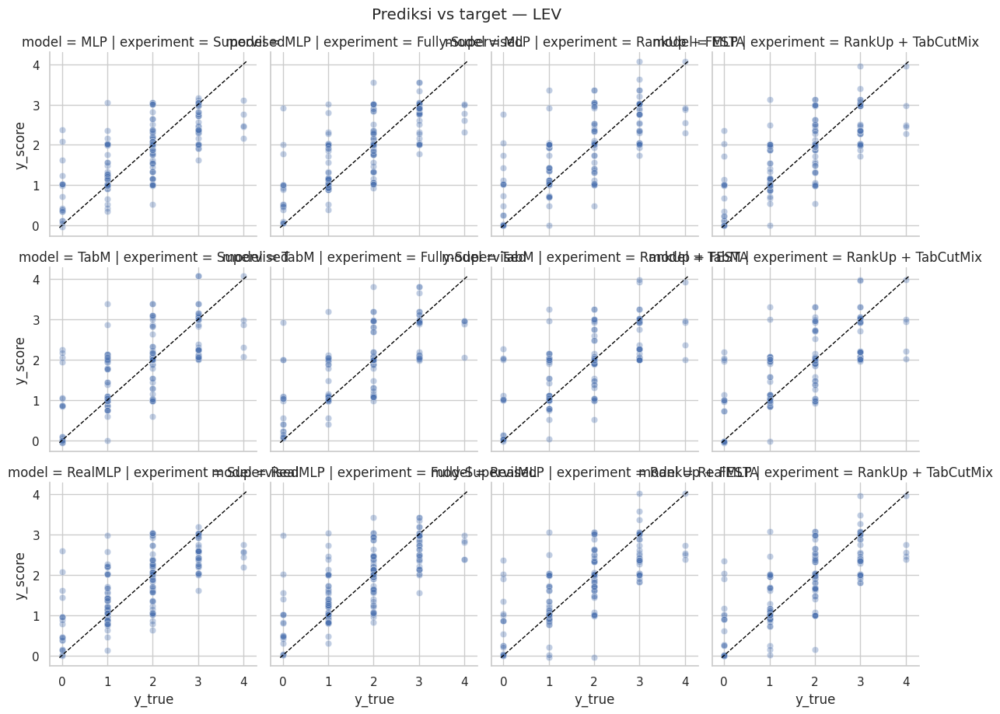

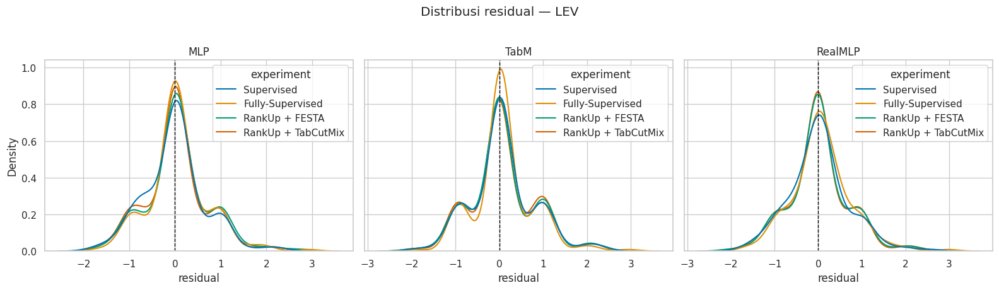

In [40]:
for dataset_name in DATASET_FILES:
    subset = predictions_df[predictions_df["dataset"] == dataset_name]
    grid = sns.relplot(
        data=subset, x="y_true", y="y_score", row="model", col="experiment",
        row_order=MODELS, col_order=EXPERIMENTS, kind="scatter", alpha=0.35, palette=PALETTE,
        height=3, aspect=1, facet_kws={"sharex": True, "sharey": True},
    )
    low, high = subset[["y_true", "y_score"]].min().min(), subset[["y_true", "y_score"]].max().max()
    for axis in grid.axes.flat:
        axis.plot([low, high], [low, high], "--", color="black", linewidth=1)
    grid.figure.suptitle(f"Prediksi vs target — {dataset_name}", y=1.02)
    grid.figure.savefig(OUTPUT_DIR / f"prediction_{DATASET_FILES[dataset_name][:-4]}.png", dpi=150, bbox_inches="tight")
    plt.show()

    figure, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
    for axis, model_name in zip(axes, MODELS):
        sns.kdeplot(
            data=subset[subset["model"] == model_name], x="residual", hue="experiment",
            hue_order=EXPERIMENTS, palette=PALETTE, common_norm=False, ax=axis,
        )
        axis.axvline(0, linestyle="--", color="black", linewidth=1)
        axis.set_title(model_name)
    figure.suptitle(f"Distribusi residual — {dataset_name}", y=1.02)
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / f"residual_{DATASET_FILES[dataset_name][:-4]}.png", dpi=150, bbox_inches="tight")
    plt.show()

# 14. File output

Setelah **Save & Run All**, unduh folder `rankup_results` dari tab Output Kaggle. Isinya:

- `metrics.csv`: lima metrik, hardware, serta waktu training dan inference tiap run.
- `predictions.csv`: target, skor kontinu, dan residual setiap sampel test.
- `history.csv`: loss per epoch.
- PNG metrik, loss, prediksi, residual, dan t-SNE untuk setiap model dan dataset.

Pada TabM, representasi t-SNE adalah rata-rata hidden representation dari `k` anggota ensemble.